# OEAS 805 Homework 2: Exploratory Data Analysis (EDA) of International Coastal Cleanup Data
### Jupyter Notebook created by Nick Carpenter for the Fall 2026 OEAS 805: Advanced Environmental Data Science course

This notebook explores the **International Coastal Cleanup** open dataset, provided by the City of Norfolk's Keep Norfolk Beautiful and
Department of Public Works (Division of Storm Water Management). The data is available through the [Norfolk OpenData Portal](https://data.norfolk.gov/) with detailed information and metadata provided [here.](https://data.norfolk.gov/Environment/International-Coastal-Cleanup/frs3-vh3y/about_data)

The International Coastal Cleanup is an annual international initiative (held annually September 1 - October 31) that removes trash from beaches and waterways. Volunteer groups identify and tabulate each piece of debris collected at a cleanup site, generating a detailed itemized count of litter types (e.g., cigarette butts, plastic bottles, fishing gear, etc.), along with summary information about the cleanup event itself (e.g., area cleaned, date, number of volunteers, volunteer hours, miles covered, total items collected, and total pounds of litter collected).

This dataset covers cleanup events in the City of Norfolk beginning in 2016. The data aims to give residents and community leaders an itemized picture of the litter found at specific sites to support trash removal efforts and encourage behavior change that reduces marine debris.

This notebook explores the dataset's structure and content, checks data types and completeness, and summarizes descriptive statistics, distributions, and relationships between variables to draw initial conclusions about coastal litter patterns in Norfolk.

I also took the EDA a step further with cartopy/ other packages to map the data. To do this, I used polygons from, or made polygons from, three datasets to represent the "Area" field in the dataset:
- Keep Norfolk Beautiful (KNB) Adopt-A-Spot (AAS) Locations (The City of Norfolk): https://arcg.is/vHHrq1
- Street Centerlines (The City of Norfolk): https://norfolkgisdata-orf.opendata.arcgis.com/datasets/ORF::street-centerline-city-of-norfolk/about
- Zoning (The City of Norfolk): https://norfolkgisdata-orf.opendata.arcgis.com/datasets/ORF::zoning/about

In [1]:
# Load the packages you will need for your analysis

# pandas is a package for data analysis and manipulation
import pandas as pd  

# seaborn is a data visualization package
import seaborn as sns  

# matplotlib is the OG python plotting library, useful for customizing plots
import matplotlib.pyplot as plt  
import matplotlib.lines as mlines # import matplotlib 2D lines module to control properties like styles, colors, widths, and markers
import matplotlib.patches as mpatches # import matplotlib module for drawing 2D geometric shapes or patches
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# cartopy is used for mapping/geospatial plotting
import cartopy.crs as ccrs  
import cartopy.feature as cfeature
import cartopy.io.img_tiles as cimgt

 # scipy.stats provides statistical functions useful for outlier detection
from scipy import stats 

# additional packages needed for bonus geospatial section
import geopandas as gpd          # extends pandas with geometry columns and spatial operations
import requests                  # used to send HTTP queries to the ArcGIS REST API endpoints
import pyproj
import numpy as np
import shapely
from shapely.ops import transform
from shapely.geometry import box
from shapely.geometry import LineString   # used to build the one custom line-buffer polygon
from shapely.ops import unary_union       # used to merge/dissolve multiple polygons into one
import shapely.validation
from adjustText import adjust_text

In [2]:
# load the .csv file with International Coastal Cleanup data

# Set the path to the correct directory for your particular computer
# this assumes the notebook lives in HW2_CODE and the data lives in a sibling folder HW2_DATA
infile = r'C:\Users\jonat\OneDrive\Documents\00Coursework\00Fall2026\OEAS805\HW2\HW2_DATA\International_Coastal_Cleanup.csv'

# Read in the .csv file. 
# In this case, we are not explicitly defining the column separator (comma) 
# because the genius who entered this data used commas as a numerical thousands separator
data = pd.read_csv(infile)
# show the data head (basically, a quick preview of the data in table format that truncates the number of entries)
data.head()

,Area,Date,Cigarette Butts,"Food Wrappers (candy, chips, etc.)",Take Out/Away Containers (Plastic),Take Out/Away Containers (Foam),Bottle Caps (Plastic),Bottle Caps (Metal),Lids (Plastic),"Straws, Stirrers",...,Tampons/Tampon Applicators,Personal Hygiene (Clean Swell),Foam Pieces,Glass Pieces,Plastic Pieces,Total Items Collected,Total Pounds of Litter Collected,Number of Volunteers,Volunteer Hours,Number of Miles
0,Ocean View Beach Park,10/27/2023,40,0,3,0,0,0,0,5,...,0,0,0,0,32,85,13,6,6.0,0.50
1,Lakewood Park,10/21/2023,20,64,16,18,107,12,79,31,...,1,0,121,0,121,"1,073",300,12,24.0,1.00
2,Plum Point Park,10/08/2023,7,30,2,6,29,2,7,15,...,0,0,18,11,19,337,90,10,30.0,0.25
3,Lafayette Park & Lavalette Boat Ramp,10/07/2023,220,166,19,55,76,42,24,17,...,0,0,198,76,188,"1,866",65,6,12.0,1.00
4,Barraud Park,10/07/2023,800,486,38,15,142,"2,488",36,149,...,0,0,31,15,13,"5,238",30,28,42.0,2.00


## Geographic context

Before exploring the data itself, the following code cell provides basic geographic context for where these cleanup events take place. The dataset does not include coordinates for individual cleanup sites, so this map shows only the general study area (Norfolk, VA), rather than specific site locations.

Map: general location of the International Coastal Cleanup study area (Norfolk, VA)


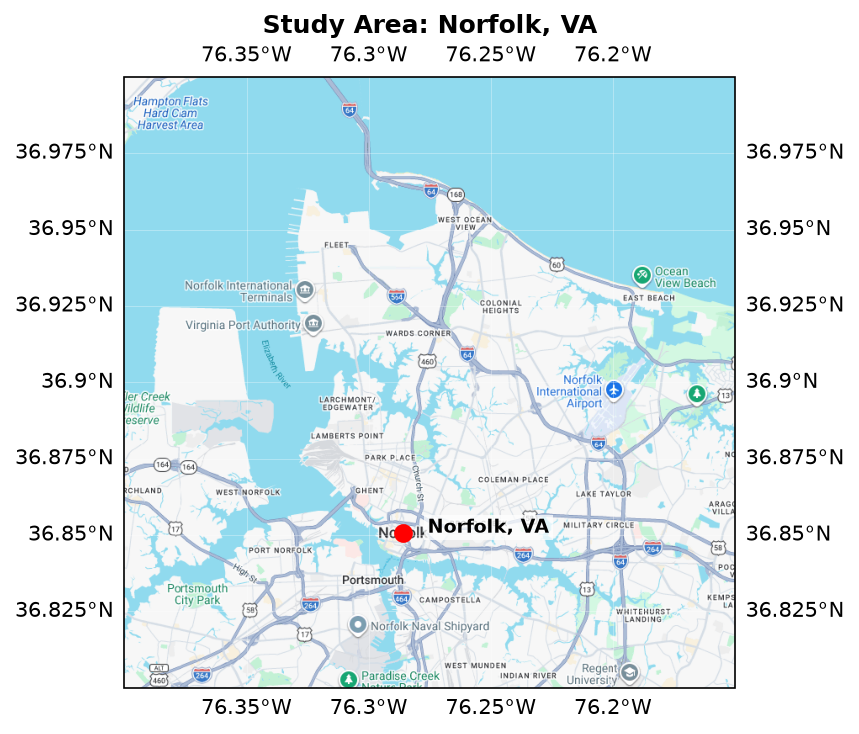

In [3]:
print("Map: general location of the International Coastal Cleanup study area (Norfolk, VA)")

# GoogleTiles(style='satellite') fetches real satellite imagery tiles,
# which gives much more visual detail and realism than vector shapefiles at this zoom level
tiler = cimgt.GoogleTiles(style='street')
# You can also replace with OSM() to fetch OpenStreetMap raster imagery if that's preferred. 

fig = plt.figure(figsize=(6,5), dpi=150)

# use the tile source's own coordinate reference system for the axes
ax = plt.axes(projection=tiler.crs)
ax.set_extent([-76.4, -76.15, 36.8, 37.0], crs=ccrs.PlateCarree())

# add the map tile imagery; the second argument is the zoom level
# (higher = more detail but more tiles to download and slower rendering)
ax.add_image(tiler, 12)

# add latitude/longitude gridlines for reference, drawn on top of the tile imagery
ax.gridlines(draw_labels=True, linewidth=0.3, color='white', alpha=0.5)

# mark the approximate location of Norfolk, VA, where all cleanup events in this dataset took place
ax.plot(-76.2859, 36.8508, marker='o', color='red', markersize=8, transform=ccrs.PlateCarree(), zorder=5)
ax.text(-76.2859 + 0.01, 36.8508, 'Norfolk, VA', transform=ccrs.PlateCarree(), fontsize=9,
        fontweight='bold', zorder=5, bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', pad=1.5))

ax.set_title('Study Area: Norfolk, VA', fontweight='bold')
plt.tight_layout()
plt.show()

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## Q1) Size of the dataset

What is the size of the dataset? How many samples/ data points (i.e., rows of data for each location + date) were recorded, and how many variables (i.e., columns of data for litter type and other information) were tracked for each one?

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [4]:
# The shape of the data 
# (nrows, ncols)
print("(# rows, # columns):") 
data.shape

(# rows, # columns):


(77, 53)

In [5]:
# Total number of individual data points in the dataframe
# nrows * ncols
print("Total # of data points (rows x columns):") 
data.size

Total # of data points (rows x columns):


4081

In [6]:
# Gives a list of all the column names in the dataframe
print("List of column names:") 
data.columns

List of column names:


Index(['Area', 'Date', 'Cigarette Butts', 'Food Wrappers (candy, chips, etc.)',
       'Take Out/Away Containers (Plastic)', 'Take Out/Away Containers (Foam)',
       'Bottle Caps (Plastic)', 'Bottle Caps (Metal)', 'Lids (Plastic)',
       'Straws, Stirrers', 'Forks, Knives, Spoons',
       'Beverage Bottles (Plastic)', 'Beverage Bottles (Glass)',
       'Beverage Cans', 'Grocery Bags (Plastic)', 'Other Plastic Bags',
       'Paper Bags', 'Cups, Plates (Paper)', 'Cups, Plates (Plastic)',
       'Cups, Plates (Foam)', 'Fishing Buoys, Pots & Traps',
       'Fishing Net & Pieces', 'Fishing Line (1 yard/meter = 1 piece)',
       'Rope (1 yard/meter = 1 piece)', 'Fishing Gear (Clean Swell)',
       '6-Pack Holders', 'Other Plastic/Foam Packaging',
       'Other Plastic Bottles (oil, bleach, etc.)', 'Strapping Bands',
       'Tobacco Packaging/Wrap', 'Other Packaging (Clean Swell)',
       'Appliances (refrigerators, washers, etc.)', 'Balloons', 'Cigar Tips',
       'Cigarette Lighters', 'Co

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## Q2) Data types

What data types are in the dataset (i.e., the data types pandas has assigned to each column)? Are all of the variables the same type? Do you have a combination of data types? 

The variable 'Area' is likely a text/categorical data type (it provides the cleanup location name), and the variable 'Date' is likely in datetime format. Since almost all variables in this dataset are counts of debris items, I expect the remaining columns to be numeric (integers), specifically whole numbers (no decimal points) for nearly all columns.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [7]:
# Print information about the data in the dataframe, including the dtype of each column
print("Data types and non-null counts per column of the dataframe:") 
data.info()

Data types and non-null counts per column of the dataframe:
<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 53 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Area                                       77 non-null     str    
 1   Date                                       77 non-null     str    
 2   Cigarette Butts                            77 non-null     str    
 3   Food Wrappers (candy, chips, etc.)         77 non-null     str    
 4   Take Out/Away Containers (Plastic)         77 non-null     int64  
 5   Take Out/Away Containers (Foam)            77 non-null     int64  
 6   Bottle Caps (Plastic)                      77 non-null     int64  
 7   Bottle Caps (Metal)                        77 non-null     str    
 8   Lids (Plastic)                             77 non-null     int64  
 9   Straws, Stirrers                           77 non-n

--------------------------------------------------------------------------------------

In the output above, most of the debris-count columns are correctly read as integers (`int64`), as expected. However, a handful of columns that should also be numeric counts — such as `Cigarette Butts`, `Food Wrappers`, `Bottle Caps (Metal)`, `Total Items Collected`, and a few others — were read in as text (`object`/`str`) instead.

This data-type inconsistency is investigated further below.

--------------------------------------------------------------------------------------

In [8]:
# Take a closer look at one of the columns that was read in as text instead of a number
print("Str column example: first 15 unique 'Cigarette Butts' entries")
data['Cigarette Butts'].unique()[:15]

Str column example: first 15 unique 'Cigarette Butts' entries


<StringArray>
[   '40',    '20',     '7',   '220',   '800',    '50',   '203',   '123',
   '655', '1,271', '1,119',    '44',    '49',    '56',    '24']
Length: 15, dtype: str

--------------------------------------------------------------------------------------

The values above reveal the issue: larger numbers in this column (and several others) are formatted with a comma as a thousands separator (e.g. `'1,271'`), which pandas cannot automatically interpret as a number. As a result, the entire column gets stored as text rather than a numeric type.

Since these are genuinely quantitative variables, the following code cells will clean this up by removing the commas and converting these columns to numeric type, and will also convert the `Date` column from text into a proper datetime type, so all fields can be used correctly in later statistical and visual analysis.

--------------------------------------------------------------------------------------

In [9]:
# Identify all columns that were incorrectly read in as text,
# excluding the two columns that legitimately should be text: 'Area' and 'Date'
print("List of columns to fix:")
text_cols = data.select_dtypes(include='str').columns
cols_to_fix = [col for col in text_cols if col not in ['Area', 'Date']]
print(cols_to_fix)

List of columns to fix:
['Cigarette Butts', 'Food Wrappers (candy, chips, etc.)', 'Bottle Caps (Metal)', 'Beverage Bottles (Glass)', 'Personal Hygiene (Clean Swell)', 'Glass Pieces', 'Plastic Pieces', 'Total Items Collected', 'Total Pounds of Litter Collected']


In [10]:
# Remove commas from these columns and convert them to numeric (integer) type
for col in cols_to_fix:
    data[col] = pd.to_numeric(data[col].str.replace(',', ''), errors='coerce')

In [11]:
# Convert the 'Date' column from text into a proper datetime type
data['Date'] = pd.to_datetime(data['Date'])

In [12]:
# Confirm the fix worked
print("Data types and non-null counts per column of the CLEAN dataframe:")
data.info()

Data types and non-null counts per column of the CLEAN dataframe:
<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 53 columns):
 #   Column                                     Non-Null Count  Dtype         
---  ------                                     --------------  -----         
 0   Area                                       77 non-null     str           
 1   Date                                       77 non-null     datetime64[us]
 2   Cigarette Butts                            77 non-null     int64         
 3   Food Wrappers (candy, chips, etc.)         77 non-null     int64         
 4   Take Out/Away Containers (Plastic)         77 non-null     int64         
 5   Take Out/Away Containers (Foam)            77 non-null     int64         
 6   Bottle Caps (Plastic)                      77 non-null     int64         
 7   Bottle Caps (Metal)                        77 non-null     int64         
 8   Lids (Plastic)                             77 n

--------------------------------------------------------------------------------------

After cleaning, all of the debris-count and summary columns are now numeric (`int64` or `float64`), `Date` is now a proper `datetime64` type, and `Area` remains as text, which is appropriate since it is a categorical/identifier field rather than a quantity.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## Q3) Missing data
Do your data columns contain missing data? Do all variables have the same number of missing data points?

This section will check whether any columns contain missing values and whether the occurrence of missing data points is evenly spread across variables or concentrated in specific ones.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [13]:
# Total number of missing values across the entire dataset
print("Total # of missing (NaN) values in the dataset:")
print(int(data.isna().sum().sum()))

Total # of missing (NaN) values in the dataset:
0


In [14]:
# Count the number of missing (NaN) values in each column
print("Total # of missing (NaN) values per column:") 
data.isna().sum()

Total # of missing (NaN) values per column:


Area                                         0
Date                                         0
Cigarette Butts                              0
Food Wrappers (candy, chips, etc.)           0
Take Out/Away Containers (Plastic)           0
Take Out/Away Containers (Foam)              0
Bottle Caps (Plastic)                        0
Bottle Caps (Metal)                          0
Lids (Plastic)                               0
Straws, Stirrers                             0
Forks, Knives, Spoons                        0
Beverage Bottles (Plastic)                   0
Beverage Bottles (Glass)                     0
Beverage Cans                                0
Grocery Bags (Plastic)                       0
Other Plastic Bags                           0
Paper Bags                                   0
Cups, Plates (Paper)                         0
Cups, Plates (Plastic)                       0
Cups, Plates (Foam)                          0
Fishing Buoys, Pots & Traps                  0
Fishing Net &

--------------------------------------------------------------------------------------

The dataset contains 0 "NaN" missing values across all 53 columns. 

Just glancing at the data.head() or the truncated table shown at the beginning of this notebook, it looks like anything without a value was given a literal value of `0` rather than being blank (or entered as NaN, -999, etc.). Since most columns represent counts or amounts of specific debris items found during a cleanup, a value of `0` is a meaningful, legitimate data point indicating 0 units of the column's variable were found at that site + date, rather than a data blank, unrecorded, or missing measurement.

However, while a `0` in an individual debris-count column is a meaningful, valid measurement, it is worth separately checking whether any entire rows contain `0` across *every* numeric column. In particular, an entry of `0` in the summary fields (`Number of Volunteers`, `Volunteer Hours`, `Number of Miles`) would not make numerical sense because a cleanup event with zero volunteers, zero hours, and zero miles logged is not a plausible real cleanup event and likely represents an unrecorded or blank entry that should be treated as a missing data point rather than a genuine measurement of zero effort.

This dataset is a case that summary statistics like `.isna().sum()` alone would not catch, since these rows technically contain no `NaN` values, only zeros, but not every instance of a `0` should be treated like missing data.

--------------------------------------------------------------------------------------

In [15]:
print("Rows where every numeric column equals 0:")

# Select all numeric columns, then flag rows where every single one of those columns equals 0
numeric_cols = data.select_dtypes(include='number').columns
all_zero_mask = (data[numeric_cols] == 0).all(axis=1)

print(f"Number of all-zero rows: {all_zero_mask.sum()}")
data.loc[all_zero_mask, ['Area', 'Date']]

Rows where every numeric column equals 0:
Number of all-zero rows: 4


,Area,Date
37,Willoughby Spit,2019-10-05
58,Oceanview Park (4th - 9th Street),2017-09-30
66,Curlew Drive (Feeder Road - Light Rail Station),2016-09-30
69,East Princess Anne Road (Park Avenue - Ballent...,2016-09-30


--------------------------------------------------------------------------------------

4 of the 77 rows have every numeric column equal to zero, including summary fields that should never realistically be zero for a recorded event (volunteers, hours, miles). 

These 4 rows are treated as missing/no-data entries and removed from the working dataset below, since keeping them would artificially inflate the apparent frequency of "zero" values and distort the summary statistics, distributions, and correlations calculated in later sections.

--------------------------------------------------------------------------------------

In [16]:
print("Removing rows with no recorded data (all numeric columns = 0):")

data = data[~all_zero_mask].reset_index(drop=True)
print(f"Updated dataset shape: {data.shape}")

Removing rows with no recorded data (all numeric columns = 0):
Updated dataset shape: (73, 53)


--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## Q4) Descriptive statistics and distributions
Provide descriptive statistics for your variables (mean, stdev, median, etc.). Boxplots, bar charts, and histograms are great for visualizing your data distributions.

The dataset contains 47 numeric debris-count columns alongside 5 summary columns (`Total Items Collected`, `Total Pounds of Litter Collected`, `Number of Volunteers`, `Volunteer Hours`, `Number of Miles`). Since visualizing every debris category is impractical, the following code cells first summarize the full set of numeric variables with descriptive statistics, then focus visualizations on the key summary variables and the debris categories found in the highest quantities overall.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [17]:
# Display descriptive statistics (count, mean, std, min, quartiles, max) for every numeric column
print("Descriptive statistics for all numeric columns:")
pd.set_option('display.max_rows', None)  # ensure all 52 numeric columns are shown, not truncated
# .T transposes the output so each row is a variable, which is easier to read with this many columns
data.describe().T

Descriptive statistics for all numeric columns:


,count,mean,min,25%,50%,75%,max,std
Date,73,2019-12-04 03:36:59.178082,2016-09-30 00:00:00,2017-09-30 00:00:00,2019-10-05 00:00:00,2021-10-23 00:00:00,2023-10-27 00:00:00,NaN
Cigarette Butts,73.0,506.506849,0.0,56.0,158.0,482.0,3639.0,847.378132
"Food Wrappers (candy, chips, etc.)",73.0,162.671233,0.0,32.0,75.0,183.0,1203.0,222.750237
Take Out/Away Containers (Plastic),73.0,19.369863,0.0,3.0,10.0,32.0,90.0,22.102983
Take Out/Away Containers (Foam),73.0,14.465753,0.0,1.0,7.0,21.0,106.0,19.177593
Bottle Caps (Plastic),73.0,103.726027,0.0,18.0,47.0,112.0,780.0,151.005543
Bottle Caps (Metal),73.0,258.821918,0.0,3.0,18.0,42.0,6269.0,947.891012
Lids (Plastic),73.0,24.630137,0.0,6.0,14.0,34.0,109.0,26.883755
"Straws, Stirrers",73.0,53.328767,0.0,11.0,26.0,73.0,368.0,62.660694
"Forks, Knives, Spoons",73.0,14.671233,0.0,2.0,7.0,21.0,136.0,20.518999


--------------------------------------------------------------------------------------

The full summary table shows that nearly every debris-count column has a mean much larger than its median (50th percentile), with a maximum value far above the 75th percentile. This pattern indicates that most variables in this dataset are right-skewed: most cleanup events collect relatively small quantities of a given item, while a handful of events collect very large quantities, pulling the mean upward. This is explored further as a potential sign of outliers in Q5.

--------------------------------------------------------------------------------------

In [18]:
# Subset just the 5 "summary-level" columns (as opposed to the 47 individual debris-item columns)
# These describe the cleanup event itself rather than counts of a specific item
print("Descriptive statistics for key summary variables:")
key_cols = ['Total Items Collected', 'Total Pounds of Litter Collected', 
            'Number of Volunteers', 'Volunteer Hours', 'Number of Miles']
data[key_cols].describe()

Descriptive statistics for key summary variables:


,Total Items Collected,Total Pounds of Litter Collected,Number of Volunteers,Volunteer Hours,Number of Miles
count,73.000000,73.000000,73.000000,73.000000,73.000000
mean,2172.321918,211.547945,19.931507,39.417808,1.614795
std,3466.509629,387.020457,27.619603,57.904256,1.481811
min,85.000000,0.000000,1.000000,1.000000,0.010000
25%,401.000000,45.000000,6.000000,10.000000,1.000000
50%,973.000000,90.000000,11.000000,22.500000,1.000000
75%,2066.000000,189.000000,23.000000,42.000000,2.000000
max,20544.000000,2545.000000,178.000000,396.000000,10.000000


Histogram: distribution of total items collected per cleanup event


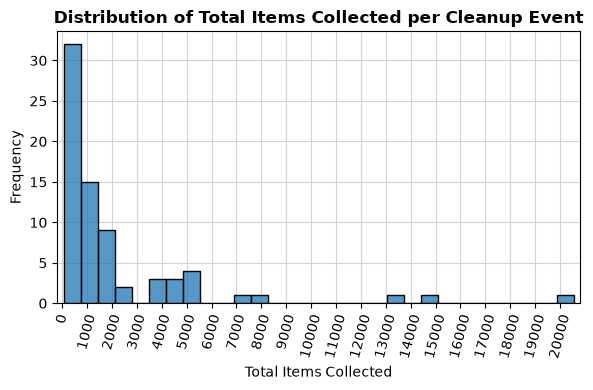

In [19]:
print("Histogram: distribution of total items collected per cleanup event")

# Create a figure/axis pair so the plot can be sized and labeled explicitly
fig, ax = plt.subplots(figsize=(6,4), dpi=100)

# Draw a light gray grid first, and push it behind the plotted bars
ax.set_axisbelow(True)
ax.grid(True, color='lightgray')

# Plot a histogram of Total Items Collected, using 30 bins to show the shape of the distribution
sns.histplot(data=data, x='Total Items Collected', bins=30, ax=ax)

# Set the x-axis ticks to appear at intervals of 1000
ax.xaxis.set_major_locator(plt.MultipleLocator(1000))

# Restrict the visible x-axis range so it starts just left of 0 and ends just right of the max value,
# rather than letting matplotlib auto-extend the axis (which was pushing the first tick to -1000)
ax.set_xlim(-200, 20800)

# Label the axes and add a bold title at the top of the plot
ax.set_xlabel('Total Items Collected')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of Total Items Collected per Cleanup Event', fontweight='bold')

plt.xticks(rotation=75)  # Rotate x-axis labels slightly so 1000-interval ticks don't overlap
plt.tight_layout()
plt.show()

--------------------------------------------------------------------------------------

The histogram confirms the right skew noted above: most cleanup events collect under roughly 2,000 items, but a small number collect far more, stretching the distribution's tail past 20,000 items.

--------------------------------------------------------------------------------------

Boxplots: key summary variables


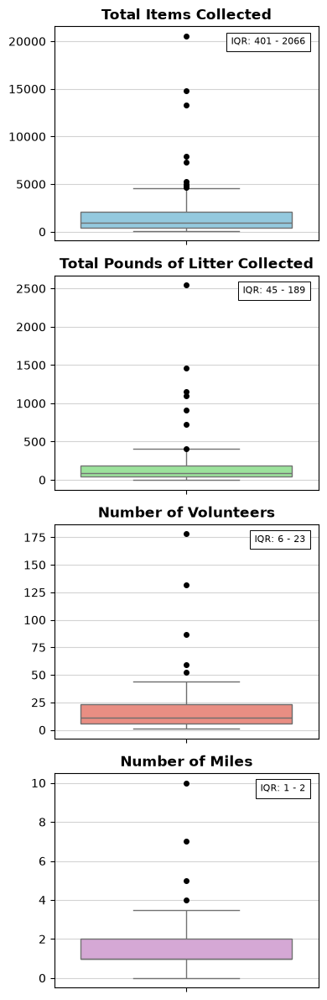

In [20]:
print("Boxplots: key summary variables")

# Define the 4 summary variables to plot, each with its own distinct fill color
# (Plotted separately since the 4 variables are on very different scales)
box_vars = ['Total Items Collected', 'Total Pounds of Litter Collected', 
            'Number of Volunteers', 'Number of Miles']
box_colors = ['skyblue', 'lightgreen', 'salmon', 'plum']

# Create a column of 4 stacked subplots (one per variable), stacked vertically so each renders clearly
fig, axes = plt.subplots(4, 1, figsize=(4,12), dpi=100)

# Style used to replace the default hollow-circle outlier markers with small solid black dots
flier_style = dict(marker='o', markerfacecolor='black', markeredgecolor='black', markersize=4)

for ax, var, color in zip(axes, box_vars, box_colors):
    # Draw a light gray grid behind each plot, pushed behind the boxplot itself
    ax.set_axisbelow(True)
    ax.grid(True, color='lightgray')

    # Draw the boxplot for this variable, using its assigned color and the black-dot outlier style
    sns.boxplot(data=data, y=var, ax=ax, color=color, flierprops=flier_style)

    # Add a bold title at the top of each subplot
    ax.set_title(var, fontweight='bold')
    ax.set_ylabel('')

    # Calculate this variable's first and third quartiles, to display in an IQR text box
    q1 = data[var].quantile(0.25)
    q3 = data[var].quantile(0.75)

    # Add a white text box with a thin black outline in the top right corner showing the IQR
    ax.text(0.95, 0.95, f'IQR: {q1:.0f} - {q3:.0f}', transform=ax.transAxes,
            ha='right', va='top', fontsize=8,
            bbox=dict(facecolor='white', edgecolor='black', linewidth=0.7))

plt.tight_layout() # Prevent axis labels/titles from overlapping between subplots
plt.show()

--------------------------------------------------------------------------------------

All four boxplots show multiple points above the upper whisker, indicating outliers. This matches the right-skewed distributions in the histogram and summary statistics, and is examined more closely in Q5.

--------------------------------------------------------------------------------------

Bar chart: mean count of the 15 most commonly found debris items per cleanup


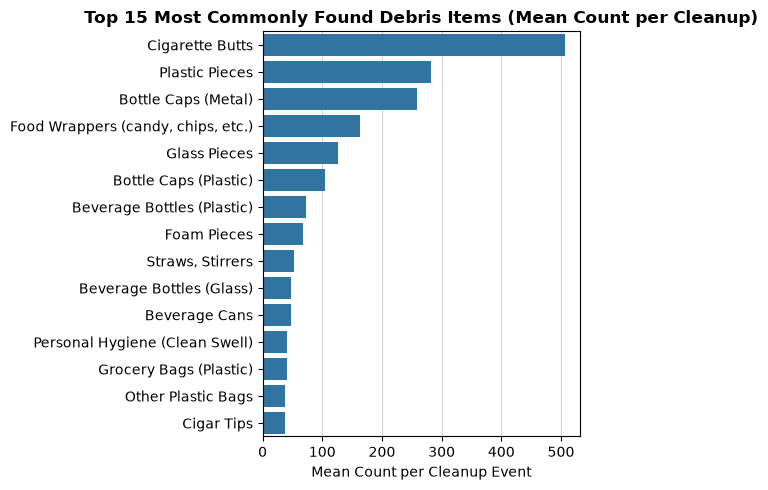

In [21]:
print("Bar chart: mean count of the 15 most commonly found debris items per cleanup")

# Build a list of just the individual debris-item columns, 
# Excluding identifier columns (Area, Date) and the summary-level columns
item_cols = [col for col in data.columns if col not in 
             ['Area', 'Date', 'Total Items Collected', 'Total Pounds of Litter Collected', 
              'Number of Volunteers', 'Volunteer Hours', 'Number of Miles']]

# Compute the average count of each debris item across all cleanup events,
# Sort from highest to lowest average, and keep only the top 15
top_items = data[item_cols].mean().sort_values(ascending=False).head(15)

# Sized the plot smaller so it renders well within the notebook width
fig, ax = plt.subplots(figsize=(6,5), dpi=100)

# Draw a light gray grid first, and push it behind the plotted bars
ax.set_axisbelow(True)
ax.grid(True, color='lightgray')

# Plot a horizontal bar chart so the (long) item names are readable on the y-axis
sns.barplot(x=top_items.values, y=top_items.index, ax=ax)
ax.set_xlabel('Mean Count per Cleanup Event')
ax.set_ylabel('')  # Item names are self-explanatory, so no y-axis label needed
ax.set_title('Top 15 Most Commonly Found Debris Items (Mean Count per Cleanup)', fontweight='bold')

plt.tight_layout() # Prevent axis labels/titles from overlapping between subplots
plt.show()

--------------------------------------------------------------------------------------

Cigarette butts are by a wide margin the most commonly collected item, averaging roughly 480 per cleanup event, well ahead of the next most common categories (plastic pieces, metal bottle caps, and food wrappers). This aligns with cigarette butts being the most (or at least one of the most) frequently littered items in coastal cleanup data generally (typically comprising 30-40% of items collected), since they are small, easily discarded, and slow to break down. Additionally, according to Truth Initiative (2023), 21% of smokers do NOT consider cigarette butts to be a form of litter. However, the majority of smokers (72%), including those who do not share this mindset, reported littering a butt on the ground at least once in their lifetime.

Source:
Truth Initiative. (2023, April 26). Tobacco and the environment. Truth Initiative. https://truthinitiative.org/research-resources/harmful-effects-tobacco/tobacco-and-environment

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## Q5) Outliers
Does your data contain outliers?

Both the descriptive statistics and the boxplots in Q4 suggest outliers in several variables. The following code cells will use the interquartile range (IQR) method to formally identify which cleanup events qualify as outliers for `Total Items Collected`, and take a closer look at what those events have in common.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [22]:
print("IQR-based outlier bounds for Total Items Collected:")

# Calculate the 25th and 75th percentiles (first and third quartiles)
q1 = data['Total Items Collected'].quantile(0.25)
q3 = data['Total Items Collected'].quantile(0.75)

# Interquartile range = spread of the middle 50% of the data
iqr = q3 - q1

# Standard IQR rule: anything beyond 1.5x the IQR past Q1/Q3 is considered an outlier
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"Lower bound: {lower_bound}")
print(f"Upper bound: {upper_bound}")

IQR-based outlier bounds for Total Items Collected:
Lower bound: -2096.5
Upper bound: 4563.5


In [23]:
print("Cleanup events flagged as outliers (Total Items Collected above upper bound):")

# Filter the dataframe down to only rows where Total Items Collected exceeds the upper bound,
# keeping just the columns needed to identify each event
outliers = data[data['Total Items Collected'] > upper_bound][['Area', 'Date', 'Total Items Collected']]

# Sort so the most extreme outliers appear first
outliers = outliers.sort_values('Total Items Collected', ascending=False)
outliers

Cleanup events flagged as outliers (Total Items Collected above upper bound):


,Area,Date,Total Items Collected
49,Barraud Park,2017-09-30,20544.0
44,Barraud Park,2018-09-30,14830.0
20,Barraud Park,2021-10-16,13269.5
54,Lambert's Point (ODU Service Learning Group),2017-09-30,7892.0
38,Barraud Park,2019-09-21,7273.0
4,Barraud Park,2023-10-07,5238.0
66,Ocean View Beach Park,2016-09-30,4904.0
64,East Ocean View (1300 - 1800 Block),2016-09-30,4904.0
9,Barraud Park,2022-10-22,4887.0
24,Harbor Park (ERT),2021-09-25,4626.0


--------------------------------------------------------------------------------------

10 cleanup events out of 73 fall above the upper IQR bound of roughly 4,564 total items, with the highest recorded event collecting over 20,000 items. Notably, several of these outlier events took place at the same site, Barraud Park, suggesting this location may consistently generate unusually high debris counts rather than these being one-off, isolated anomalies. This could reflect the site's proximity to a heavy debris source (e.g., stormwater outfall, high foot traffic, or a semi-enclosed area where litter accumulates), and may be worth flagging as a variable to look into further, such as by checking whether `Number of Volunteers` or `Number of Miles` covered were also unusually high at these events.

--------------------------------------------------------------------------------------

In [24]:
print("Number of Volunteers and Number of Miles at the flagged outlier events:")

# Use the same row indices identified as outliers above to pull in additional context columns
# (Number of Volunteers, Number of Miles) to check whether these events were simply larger in scale
data.loc[outliers.index, ['Area', 'Date', 'Total Items Collected', 'Number of Volunteers', 'Volunteer Hours','Number of Miles']]

Number of Volunteers and Number of Miles at the flagged outlier events:


,Area,Date,Total Items Collected,Number of Volunteers,Volunteer Hours,Number of Miles
49,Barraud Park,2017-09-30,20544.0,132,396.0,1.0
44,Barraud Park,2018-09-30,14830.0,39,78.0,2.0
20,Barraud Park,2021-10-16,13269.5,87,174.0,3.0
54,Lambert's Point (ODU Service Learning Group),2017-09-30,7892.0,178,222.5,10.0
38,Barraud Park,2019-09-21,7273.0,29,43.5,2.0
4,Barraud Park,2023-10-07,5238.0,28,42.0,2.0
66,Ocean View Beach Park,2016-09-30,4904.0,15,45.0,1.0
64,East Ocean View (1300 - 1800 Block),2016-09-30,4904.0,2,4.0,1.0
9,Barraud Park,2022-10-22,4887.0,35,52.5,1.5
24,Harbor Park (ERT),2021-09-25,4626.0,52,104.0,1.5


--------------------------------------------------------------------------------------

The comparison above shows a mixed picture with a few outliers that coincide with larger-scale efforts. The Lambert's Point event collected 7,892 items with 178 volunteers over 10 miles, the largest volunteer turnout and distance covered in the dataset, so its high total is plausibly just a function of a bigger cleanup. 

However, most Barraud Park outliers do not follow this pattern: for example, the event with 14,830 items involved only 39 volunteers over 2 miles, and the event with 7,273 items involved just 29 volunteers over 2 miles, both modest in scale. 

The East Ocean View event is even more striking, collecting 4,904 items with only 2 volunteers covering 1 mile for 4 hours. Looking at this now, I'm not sure whether this was a typo in the entry (maybe they meant to enter 20 volunteers instead of 2 and 40 hours instead of 4 into the table?). Otherwise, those 2 volunteers are extremely fast, productive, and deserve some kind of award! For comparison, the same amount of litter (4,904 items) over the same distance (1 mile) took far more volunteers (15 total) and volunteer hours (45) at Ocean View Beach Park on the same date.

This potentially incorrect volunteer count/hours entry (or, if correct, the very impressive efforts of 2 volunteers) aside, the frequency of locations in many of these outliers could support the earlier hypothesis that Barraud Park (and possibly a few other sites) may be genuine debris hotspots.

--------------------------------------------------------------------------------------

In [25]:
print("Outlier rate by Area, controlling for how often each site was cleaned:")

# Count how many total cleanup events occurred at each area (frequency in the full dataset)
area_totals = data['Area'].value_counts()

# Count how many of the flagged outlier events occurred at each area
area_outlier_counts = outliers['Area'].value_counts()

# Divide outlier count by total count per area to get each area's outlier RATE,
# rather than just its raw outlier count, to control for sampling frequency
outlier_rate = (area_outlier_counts / area_totals).dropna().sort_values(ascending=False)

print(outlier_rate)
print(f"\nOverall outlier rate across all events: {len(outliers) / len(data):.3f}")

Outlier rate by Area, controlling for how often each site was cleaned:
Area
Barraud Park                                    1.000000
East Ocean View (1300 - 1800 Block)             1.000000
Lambert's Point (ODU Service Learning Group)    1.000000
Harbor Park (ERT)                               0.200000
Ocean View Beach Park                           0.142857
Name: count, dtype: float64

Overall outlier rate across all events: 0.137


--------------------------------------------------------------------------------------

Before concluding that Barraud Park is a genuine debris hotspot, it's worth checking whether it simply appears more often in the dataset than other sites, which alone would make it more likely to show up in an outlier list. Controlling for this by looking at each area's outlier *rate* (outlier events divided by total events at that site, rather than raw outlier count) addresses this concern: Barraud Park was cleaned 6 times total, and all 6 of those events (100%) were flagged as outliers, compared to an overall outlier rate of only about 13.7% across the dataset. 

By contrast, Ocean View Beach Park is the most frequently cleaned site in the dataset (7 times) but has an outlier rate of only about 14.3%, close to what would be expected simply from frequent sampling. This comparison suggests the observed Barraud Park pattern is not due to sampling bias from more frequent visits. However, this outlier interpretation only means Barraud Park generated unusually high debris counts relative to other *monitored* sites, not relative to all coastal areas in Norfolk, since this dataset cannot provide information on sites that did not receive cleanup efforts.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## Q5 Bonus) Mapping cleanup site locations

The dataset does not include coordinates for individual cleanup sites, only the `Area` name. To visualize where cleanups actually occurred, the following code cells match each unique `Area` to a real-world polygon using three City of Norfolk / Keep Norfolk Beautiful GIS layers (Adopt-A-Spot Locations, Street Centerline, and Zoning), following a manually curated crosswalk (`area_geometry_lookup.csv`) built by cross-referencing each cleanup location against these layers.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [26]:
# REST API endpoints for the 3 City of Norfolk / Keep Norfolk Beautiful GIS layers used to resolve
# each cleanup Area into a real-world polygon
# Get these from each Hub page's "APIs" > "ArcGIS GeoServices REST API" link
AAS_URL = 'https://services2.arcgis.com/fUAsosS8WXl3mXcn/ArcGIS/rest/services/AAS_Locations_Public_View/FeatureServer/0'
STREET_URL = 'https://gisshare.norfolk.gov/pubserver/rest/services/OpenData/Public_Works/FeatureServer/1'
ZONING_URL = 'https://gisshare.norfolk.gov/pubserver/rest/services/OpenData/Planning/FeatureServer/1'

In [27]:
print("Loading Area-to-geometry crosswalk table:")

# This table maps each unique Area name in the working dataset to the layer (AAS, Street, Zoning,
# or Custom) and attribute value(s) needed to look up its real-world polygon
lookup = pd.read_csv(r'C:\Users\jonat\OneDrive\Documents\00Coursework\00Fall2026\OEAS805\HW2\HW2_DATA\area_geometry_lookup.csv')

print(f"Loaded {len(lookup)} unique Area entries.")
lookup.head()

Loading Area-to-geometry crosswalk table:
Loaded 36 unique Area entries.


,Area,Source,Match_1,Match_2,Match_3,Block_Min,Block_Max,Custom_Lat1,Custom_Lon1,Custom_Lat2,Custom_Lon2,Custom_Buffer_M
0,100 East Ocean View Ave,AAS,Ocean View Ave. from 1st View St to Sherwood Pl,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Admiral Taussig Boulevard (Granby Street - Eas...,AAS,Admiral Taussig Blvd from Granby to E Little C...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Barraud Park,AAS,Barraud Park,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Bay Dunes Drive,Zoning,136989,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Bayview Elementary/East Bayview Boulevard,Street,E BAYVIEW BOULEVARD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Helper/ resolver functions

In [28]:
# Generic query helper
def query_layer(service_url, where_clause, out_fields='*'):
    """
    Query an ArcGIS REST FeatureServer layer and return the results as a GeoDataFrame.

    Parameters:
        service_url  - base URL of the FeatureServer layer (e.g. .../FeatureServer/0)
        where_clause - SQL-style filter string (e.g. "SiteName = 'Barraud Park'")
        out_fields   - comma-separated list of fields to return (default: all fields)

    Returns:
        A GeoDataFrame of matching features, reprojected to WGS84 (lat/lon, EPSG:4326)
        so every geometry in this notebook shares the same coordinate system.
    """
    # Build the query parameters expected by the ArcGIS REST API's /query endpoint
    params = {
        'where': where_clause,
        'outFields': out_fields,
        'f': 'geojson',   # request GeoJSON output, which geopandas can read directly
        'outSR': 4326     # request coordinates already reprojected to WGS84 lat/lon
    }

    # Send the HTTP GET request and raise an error if the server returns a failure status
    resp = requests.get(service_url + '/query', params=params)
    resp.raise_for_status()
    data = resp.json()

    # If nothing matched the query, return an empty (but correctly structured) GeoDataFrame
    # rather than letting from_features() fail on an empty features list
    if 'features' not in data or len(data['features']) == 0:
        return gpd.GeoDataFrame(columns=[out_fields, 'geometry'], geometry='geometry', crs='EPSG:4326')

    return gpd.GeoDataFrame.from_features(data['features'], crs='EPSG:4326')

In [29]:
# AAS Locations resolver
def get_aas_geometry(site_names):
    """
    Given a list of one or more SiteName values (to be merged/dissolved into one geometry),
    fetch each matching polygon from the AAS Locations layer.

    If more than one polygon shares the same SiteName, resolve the duplicate by preferring
    Status = 'Active' entries, then picking the single largest polygon by area among the
    remaining candidates. If there is only one match for a name, it is used as-is with no
    Active/largest filtering needed.
    """
    pieces = []  # Collects one resolved geometry per name in site_names

    for name in site_names:
        # Escape any single quotes in the name so they don't break the SQL-style WHERE clause
        safe_name = name.replace("'", "''")
        where = f"SiteName = '{safe_name}'"
        gdf = query_layer(AAS_URL, where)

        if len(gdf) == 0:
            # No match at all for this name — flag it rather than silently skipping
            print(f"  WARNING: no AAS match found for '{name}'")
            continue

        elif len(gdf) > 1:
            # Multiple polygons share this name: first narrow down to Active status,
            # falling back to all candidates if none are marked Active
            active = gdf[gdf['Status'] == 'Active']
            candidates = active if len(active) > 0 else gdf

            # Reproject to a projected CRS (meters) before measuring area, since area
            # calculated directly from lat/lon degrees would be inaccurate
            candidates_proj = candidates.to_crs(epsg=3857)
            largest_idx = candidates_proj.geometry.area.idxmax()
            geom = candidates.loc[largest_idx, 'geometry']

        else:
            # Exactly one match: use it directly, no Active/largest logic needed
            geom = gdf.iloc[0]['geometry']

        pieces.append(geom)

    if not pieces:
        return None  # Every component name failed to match anything

    # Merge/dissolve all resolved component geometries into a single (possibly multi-part) geometry
    return unary_union(pieces)

In [30]:
# Street Centerline resolver
def get_street_geometry(fullname, block_min=None, block_max=None, buffer_m=5):
    """
    Query the Street Centerline layer by FULLNAME, optionally restrict to a block range,
    then buffer the resulting street segment(s) by buffer_m meters on each side to turn
    the line(s) into a polygon representing the cleanup area along that street.
    """
    safe_name = fullname.replace("'", "''")
    where = f"FULLNAME = '{safe_name}'"

    # only request FULLNAME and BLOCK, since geometry and these two fields are all this function needs
    gdf = query_layer(STREET_URL, where, out_fields='FULLNAME,BLOCK')

    if len(gdf) == 0:
        print(f"  WARNING: no Street match found for '{fullname}'")
        return None

    if pd.notna(block_min) and pd.notna(block_max):
        # BLOCK is stored as a text field in this layer, not numeric, so a numeric range filter
        # cannot be safely done in the SQL WHERE clause — instead, convert to numeric here in
        # pandas and filter client-side. errors='coerce' turns any non-numeric BLOCK values into
        # NaN rather than raising, so they're simply excluded by the range comparison below
        block_numeric = pd.to_numeric(gdf['BLOCK'], errors='coerce')
        mask = (block_numeric >= block_min) & (block_numeric <= block_max)
        gdf = gdf[mask]

        if len(gdf) == 0:
            print(f"  WARNING: '{fullname}' matched, but none fell in block range {block_min}-{block_max}")
            return None

    # Reproject to a projected CRS (meters) before buffering, since buffering directly in
    # lat/lon degrees would produce a badly distorted (non-uniform) buffer distance
    gdf_proj = gdf.to_crs(epsg=3857)

    # Merge all matching street segments into a single line before buffering,
    # so the buffer forms one continuous polygon rather than separate overlapping pieces
    merged_line = unary_union(gdf_proj.geometry)

    # cap_style=3 is shapely's "square" cap, which extends the buffer past each line endpoint
    # by buffer_m (matching the literal word "square" as requested). Note: Esri's own "Square"
    # end type in ArcGIS Pro/tools instead means a FLAT cutoff exactly at the endpoint
    # (shapely's cap_style=2) — switch to cap_style=2 here if the resulting polygon looks
    # longer than expected at the street's ends.
    buffered = merged_line.buffer(buffer_m, cap_style=3)

    # Reproject the buffered polygon back to WGS84 for consistency with the rest of the notebook
    buffered_gdf = gpd.GeoSeries([buffered], crs='EPSG:3857').to_crs(epsg=4326)
    return buffered_gdf.iloc[0]

In [31]:
# Zoning resolver
def get_zoning_geometry(objectids):
    """
    Given one or more OBJECTID values, fetch the corresponding Zoning polygons and
    merge/dissolve them into a single geometry (used when a cleanup Area spans more
    than one adjacent zoning parcel).
    """
    # OBJECTID values arrive as floats from pandas (since the column may contain NaNs
    # elsewhere), so convert to int first, then build a comma-separated SQL IN-list
    ids_str = ','.join(str(int(float(oid))) for oid in objectids)
    where = f"OBJECTID IN ({ids_str})"
    gdf = query_layer(ZONING_URL, where)

    if len(gdf) == 0:
        print(f"  WARNING: no Zoning match found for OBJECTIDs {objectids}")
        return None

    return unary_union(gdf.geometry)

In [32]:
# Custom geometry helper
def get_custom_geometry(lat1, lon1, lat2, lon2, buffer_m):
    """
    Build a polygon for the one 'Custom Way' entry (Beach - Cottage Place Beach to
    North Beach View) by drawing a straight line between two lat/lon points and
    buffering it by buffer_m meters on each side.
    """
    # Shapely expects coordinates as (x, y), i.e. (longitude, latitude) — the reverse
    # order from how lat/lon are usually written, so this is easy to get backwards
    line = LineString([(lon1, lat1), (lon2, lat2)])

    # Reproject to a projected CRS (meters) before buffering, for the same reason as in
    # get_street_geometry — buffering directly in lat/lon degrees distorts the distance
    line_gdf = gpd.GeoSeries([line], crs='EPSG:4326').to_crs(epsg=3857)
    buffered = line_gdf.iloc[0].buffer(buffer_m, cap_style=3)

    buffered_gdf = gpd.GeoSeries([buffered], crs='EPSG:3857').to_crs(epsg=4326)
    return buffered_gdf.iloc[0]

### Main Loop

In [33]:
print("Resolving geometry for each unique Area...")

geometries = []  # Will hold one resolved geometry (or None) per row of the lookup table

for _, row in lookup.iterrows():
    print(f"Processing: {row['Area']} ({row['Source']})")
    geom = None

    if row['Source'] == 'AAS':
        # Gather up to 3 possible component names to merge (Match_2/Match_3 are often blank)
        names = [v for v in [row['Match_1'], row['Match_2'], row['Match_3']] if pd.notna(v)]
        geom = get_aas_geometry(names)

    elif row['Source'] == 'Street':
        geom = get_street_geometry(row['Match_1'], row['Block_Min'], row['Block_Max'])

    elif row['Source'] == 'Zoning':
        ids = [v for v in [row['Match_1'], row['Match_2'], row['Match_3']] if pd.notna(v)]
        geom = get_zoning_geometry(ids)

    elif row['Source'] == 'Custom':
        geom = get_custom_geometry(row['Custom_Lat1'], row['Custom_Lon1'],
                                    row['Custom_Lat2'], row['Custom_Lon2'], row['Custom_Buffer_M'])

    # Source == 'None' (SPOT- Military Gardens, Wetland) intentionally leaves geom as None,
    # since no location could be determined for these two entries

    geometries.append(geom)

# Attach the resolved geometries as a new column and convert to a GeoDataFrame
lookup['geometry'] = geometries
area_geometries = gpd.GeoDataFrame(lookup, geometry='geometry', crs='EPSG:4326')

# Summarize how many areas were successfully resolved, and list any that were not
found = area_geometries['geometry'].notna().sum()
print(f"\nResolved geometry for {found} of {len(area_geometries)} areas.")
area_geometries[area_geometries['geometry'].isna()][['Area', 'Source']]

Resolving geometry for each unique Area...
Processing: 100 East Ocean View Ave (AAS)
Processing: Admiral Taussig Boulevard (Granby Street - East Little Creek Boulevard) (AAS)
Processing: Barraud Park (AAS)
Processing: Bay Dunes Drive (Zoning)
Processing: Bayview Elementary/East Bayview Boulevard (Street)
Processing: Beach (21st Bay Street - 30th Bay Street) (Zoning)
Processing: Beach (Cottage Place Beach - North Beach View) (Custom)
Processing: Community Beach Park (AAS)
Processing: Curlew Drive (Feeder Road - Light Rail Station) (AAS)
Processing: East Ocean View (AAS)
Processing: East Ocean View (1300 - 1800 Block) (Street)
Processing: East Ocean View (1300 - 1900 Block) (Street)
Processing: East Ocean View Rec Center (AAS)
Processing: East Oceanview Community Park (AAS)
Processing: East Princess Anne Road (Park Avenue - Ballentine Boulevard) (AAS)
Processing: Harbor Park (ERT) (AAS)
Processing: Lafayette Park & Lavalette Boat Ramp (AAS)
Processing: Lakewood Park (AAS)
Processing: Lam

,Area,Source
29,SPOT- Military Gardens,NaN
34,Wetland (Poppe and Somee),NaN


In [34]:
print("Filtering to only successfully resolved geometries, and repairing any invalid ones:")

# Drop the 2 areas with no resolved geometry (SPOT- Military Gardens, Wetland) —
# add_geometries() cannot plot a None value, which is the likely cause of the GEOSException
plottable = area_geometries[area_geometries['geometry'].notna()].copy()

# .buffer(0) is a common trick to repair minor topology issues (e.g. self-intersections)
# that can occur after unary_union or buffering operations, without changing the polygon's
# visible shape — this guards against the same GEOSException being triggered by an
# invalid (rather than missing) geometry
plottable['geometry'] = plottable['geometry'].buffer(0)

print(f"Plotting {len(plottable)} of {len(area_geometries)} resolved areas.")

Filtering to only successfully resolved geometries, and repairing any invalid ones:
Plotting 34 of 36 resolved areas.


In [35]:
# Diagnostic Cell: Double check that all the geometries are valid polygons
print("Checking each geometry for validity and type issues:")

for idx, row in plottable.iterrows():
    geom = row['geometry']
    print(f"{row['Area']}: type={geom.geom_type}, valid={geom.is_valid}, area={geom.area:.8f}")
    if not geom.is_valid:
        print(f"  --> INVALID: {shapely.validation.explain_validity(geom)}")

Checking each geometry for validity and type issues:
100 East Ocean View Ave: type=Polygon, valid=True, area=0.00000235
Admiral Taussig Boulevard (Granby Street - East Little Creek Boulevard): type=Polygon, valid=True, area=0.00000081
Barraud Park: type=Polygon, valid=True, area=0.00001047
Bay Dunes Drive: type=Polygon, valid=True, area=0.00000293
Bayview Elementary/East Bayview Boulevard: type=MultiPolygon, valid=True, area=0.00000320
Beach (21st Bay Street - 30th Bay Street): type=Polygon, valid=True, area=0.00001005
Beach (Cottage Place Beach - North Beach View): type=Polygon, valid=True, area=0.00000194
Community Beach Park: type=Polygon, valid=True, area=0.00000467
Curlew Drive (Feeder Road - Light Rail Station): type=Polygon, valid=True, area=0.00000189
East Ocean View: type=Polygon, valid=True, area=0.00000153
East Ocean View (1300 - 1800 Block): type=Polygon, valid=True, area=0.00000136
East Ocean View (1300 - 1900 Block): type=Polygon, valid=True, area=0.00000136
East Ocean Vi

In [36]:
# geometry cleaning helper function before mapping/ adding working dataset info
def clean_geometry(geom):
    """
    Repair a geometry for safe use with cartopy's GEOS-based reprojection/clipping.
    Combines three fixes:
      1. make_valid() repairs any topological invalidity (self-intersections, etc.)
      2. set_precision() snaps all coordinates to a coarse grid, which eliminates the
         floating-point noise (near-duplicate or near-collinear vertices) left over from
         unary_union()/buffer() operations.
      3. simplify() makes a tiny (sub-meter) adjustment to vertex positions, which works
         around a known cartopy bug where its internal reprojection step can occasionally
         produce a ring whose start/end coordinates don't exactly match after transforming
         into the tile imagery's projection (raising "Points of LinearRing do not form a
         closed linestring"), even when shapely considers the input geometry fully valid.
    """
    if geom is None:
        return None

    fixed = shapely.make_valid(geom)

    if fixed.geom_type == 'GeometryCollection':
        polys = [g for g in fixed.geoms if g.geom_type in ('Polygon', 'MultiPolygon')]
        if not polys:
            return None
        fixed = shapely.unary_union(polys)

    fixed = shapely.set_precision(fixed, grid_size=1e-7)

    # tiny simplification tolerance (~1cm in degrees) — small enough not to visibly change
    # the polygon's shape, but enough to sidestep the cartopy reprojection bug above
    fixed = fixed.simplify(1e-7, preserve_topology=True)

    return fixed

In [37]:
print("Pre-projecting geometries into Web Mercator (EPSG:3857) to bypass cartopy's internal reprojection:")
# Build a coordinate transformer from lat/lon (EPSG:4326, what our geometries are currently in)
# to Web Mercator (EPSG:3857), which is the projection the GoogleTiles satellite imagery uses.
# always_xy=True ensures the transformer expects/returns (longitude, latitude) order, matching
# how shapely geometries are structured, rather than pyproj's sometimes-default (lat, lon) order
project = pyproj.Transformer.from_crs('EPSG:4326', 'EPSG:3857', always_xy=True).transform

# Apply the transform to every geometry ourselves, ahead of time, so that when we hand these
# to add_geometries() later, cartopy has no reprojection left to do internally — this avoids
# the buggy internal reprojection/clipping step that was raising the GEOSException
plottable['geometry_3857'] = list(plottable['geometry'].apply(lambda g: transform(project, g)))

print(f"Projected {len(plottable)} geometries.")

Pre-projecting geometries into Web Mercator (EPSG:3857) to bypass cartopy's internal reprojection:
Projected 34 geometries.


### Adding an effort-normalized metric

Before joining metrics to the mapped geometries, the following code cell adds one more derived variable: items collected per volunteer-hour. This normalizes debris counts by the cleanup effort required to find them, which helps distinguish a site that's high-yield because it's genuinely debris-dense from one that's high-yield simply because it received a lot of volunteer effort—directly relevant to the effort-vs-hotspot question raised in Q5.

In [38]:
print("Adding an effort-normalized metric: items collected per volunteer-hour")

# Items collected per volunteer-hour, a rough measure of debris "density" at a site independent
# of how much cumulative effort went into finding it. A site with a high value here is yielding
# a lot of debris relative to the effort spent, while a low value suggests debris was sparse even
# with substantial searching
data['Items per Volunteer Hour'] = data['Total Items Collected'] / data['Volunteer Hours']

# Guard against division by zero (Volunteer Hours == 0), which would produce inf rather than NaN.
# The Q3 cleaning step already removed all-zero rows, so this shouldn't find anything, but this
# check confirms that rather than assuming it
n_inf = np.isinf(data['Items per Volunteer Hour']).sum()
print(f"Rows with an undefined (infinite) ratio due to 0 Volunteer Hours: {n_inf}")
data['Items per Volunteer Hour'] = data['Items per Volunteer Hour'].replace([np.inf, -np.inf], np.nan)

Adding an effort-normalized metric: items collected per volunteer-hour
Rows with an undefined (infinite) ratio due to 0 Volunteer Hours: 0


### Joining average cleanup metrics to the mapped geometries

`area_geometries` contains only location information. To color the map by litter data, the following code cell joins in the average value of 4 summary-level variables (`Total Items Collected`, `Total Pounds of Litter Collected`, `Number of Volunteers`, `Number of Miles`) and the 3 most common debris categories identified in Q4 (`Cigarette Butts`, `Plastic Pieces`, `Bottle Caps (Metal)`), averaged across all of an Area's recorded cleanup events rather than summed, so that a site visited many times isn't automatically ranked higher just for being cleaned up more often.

Note: this averaging groups the already-cleaned `data` DataFrame by `Area` alone, or by each geometry instance (rather than joining information by matching Area and Date together/ by every unique data entry). Since each Area's geometry-lookup information does not vary by Date, this produces the same result as a combined Area+Date join would, without the added complexity, and it automatically excludes the 4 all-zero "no data" rows already removed in Q3.

In [39]:
print("Averaging cleanup metrics per Area, and joining them to the mapped geometries:")

# Assumption: "4 summary-level variables" refers to the same 4 used in the Q4 boxplots
# (Total Items Collected, Total Pounds of Litter Collected, Number of Volunteers, Number of Miles).
# Swap this list if a different set was intended — everything downstream adapts automatically.
summary_cols = ['Total Items Collected', 'Total Pounds of Litter Collected',
                'Number of Volunteers', 'Number of Miles']

# The 3 most common debris categories identified in the Q4 bar chart
top_debris_cols = ['Cigarette Butts', 'Plastic Pieces', 'Bottle Caps (Metal)']

# The effort-normalized metric added in the subsection above
derived_cols = ['Items per Volunteer Hour']

# Create the columns to contain information joined to the mapped geometries
metric_cols = summary_cols + top_debris_cols + derived_cols

# Average (not sum) each metric across all of an Area's recorded cleanup events, giving one
# representative value per Area rather than one row per event
area_averages = data.groupby('Area')[metric_cols].mean()

# Left-merge onto plottable (not data), so every mapped geometry is kept even if no matching
# averages exist for it — those rows simply get NaN in the new columns
plottable = plottable.merge(area_averages, on='Area', how='left')

# Report which mapped Areas ended up with no data to color by, for transparency
no_data = plottable[plottable[metric_cols].isna().any(axis=1)]['Area'].tolist()
print(f"Areas with geometry but no cleanup data available: {no_data}")
plottable.head()

Averaging cleanup metrics per Area, and joining them to the mapped geometries:
Areas with geometry but no cleanup data available: ['Curlew Drive (Feeder Road - Light Rail Station)', 'East Princess Anne Road (Park Avenue - Ballentine Boulevard)', 'Oceanview Park (4th - 9th Street)']


,Area,Source,Match_1,Match_2,Match_3,Block_Min,Block_Max,Custom_Lat1,Custom_Lon1,Custom_Lat2,...,geometry,geometry_3857,Total Items Collected,Total Pounds of Litter Collected,Number of Volunteers,Number of Miles,Cigarette Butts,Plastic Pieces,Bottle Caps (Metal),Items per Volunteer Hour
0,100 East Ocean View Ave,AAS,Ocean View Ave. from 1st View St to Sherwood Pl,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"POLYGON ((-76.25373 36.95608, -76.25352 36.956...","POLYGON ((-8488526.460399996 4432986.4961, -84...",236.000000,20.000000,5.000000,0.500000,103.000000,5.000000,14.00,23.600000
1,Admiral Taussig Boulevard (Granby Street - Eas...,AAS,Admiral Taussig Blvd from Granby to E Little C...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"POLYGON ((-76.27205 36.918, -76.27204 36.91822...",POLYGON ((-8490566.230200002 4427682.725400004...,489.000000,60.000000,10.000000,1.000000,71.000000,125.000000,5.00,24.450000
2,Barraud Park,AAS,Barraud Park,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"POLYGON ((-76.26606 36.86505, -76.26589 36.865...",POLYGON ((-8489899.463600004 4420313.073400001...,11006.916667,684.166667,58.333333,1.916667,2049.166667,1715.666667,2815.00,117.210648
3,Bay Dunes Drive,Zoning,136989,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"POLYGON ((-76.24857 36.95343, -76.24804 36.953...",POLYGON ((-8487952.435944766 4432617.959968314...,237.000000,60.000000,3.000000,1.000000,126.000000,10.000000,0.00,26.333333
4,Bayview Elementary/East Bayview Boulevard,Street,E BAYVIEW BOULEVARD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"MULTIPOLYGON (((-76.24259 36.93402, -76.24223 ...",MULTIPOLYGON (((-8487286.368310003 4429913.823...,910.750000,43.750000,14.250000,3.062500,239.250000,79.500000,4.75,58.390873


### Reusable map-drawing helpers

The following code cells define two small helper functions used by every map below: one that draws a single polygon in the fill → black outline → colored border style (with the fill/border color as a parameter, so the same function works for both a fixed color and a data-driven choropleth color), and one that adds a small Area-name label near each polygon's top-right corner. A separate cell then splits the mapped Areas into North and South Norfolk halves at approximately 36.9°N for the two zoomed-in maps.

In [40]:
# Not technically a helper function, but before mapping we're going to remove geometries that only contain 0s
# (i.e., only missing data entry/ entries in the geometry)
print("Removing mapped Areas that have geometry but no underlying cleanup data:")

# These are Areas whose only recorded cleanup event was one of the 4 all-zero "no data" rows
# removed back in Q3 — they resolved to a real polygon, but have nothing to report or color by.
# Checking one metric column (rather than all of them) is sufficient here, since these columns
# were all aggregated from the same underlying rows in `data`: if zero rows matched an Area,
# every one of its metric columns ends up NaN together, not just some of them.
no_data_mask = plottable['Total Items Collected'].isna()

removed_areas = plottable.loc[no_data_mask, 'Area'].tolist()
print(f"Removing {len(removed_areas)} area(s) with no cleanup data: {removed_areas}")

plottable = plottable[~no_data_mask].reset_index(drop=True)
print(f"Remaining mapped areas: {len(plottable)}")

Removing mapped Areas that have geometry but no underlying cleanup data:
Removing 3 area(s) with no cleanup data: ['Curlew Drive (Feeder Road - Light Rail Station)', 'East Princess Anne Road (Park Avenue - Ballentine Boulevard)', 'Oceanview Park (4th - 9th Street)']
Remaining mapped areas: 31


In [41]:
# Not technically a helper function, but before mapping we're going to pre-split the data
# into two mapping sections to zoom into these areas
print("Splitting mapped Areas into North and South Norfolk halves at approximately 36.9°N:")

# Convert to a plain list first, which strips away the (incorrect) CRS label geometry_3857
# inherited from the .apply() call that created it — the coordinates themselves are already
# correctly in Web Mercator meters, just mislabeled as EPSG:4326 at the column level
centroids_3857 = gpd.GeoSeries(list(plottable['geometry_3857']), crs='EPSG:3857').centroid

# Convert just the resulting centroid points back to lat/lon (EPSG:4326), so the 36.9 comparison
# below is in familiar latitude degrees
centroids_4326 = centroids_3857.to_crs(epsg=4326)
plottable['centroid_lat'] = centroids_4326.y

north_half = plottable[plottable['centroid_lat'] >= 36.9]
south_half = plottable[plottable['centroid_lat'] < 36.9]

print(f"North Norfolk: {len(north_half)} areas, South Norfolk: {len(south_half)} areas")

Splitting mapped Areas into North and South Norfolk halves at approximately 36.9°N:
North Norfolk: 19 areas, South Norfolk: 12 areas


In [42]:
# Cloropleth map fill color helper function
def get_fill_color(value, cmap, norm):
    """
    Return a color for a polygon's fill/border based on a data value.
    Returns light gray if the value is missing (NaN), or a colormap color scaled by norm otherwise.
    """
    # NaN indicates this Area had no cleanup data to average (see the merge cell's printed list) —
    # use a neutral gray so it reads clearly as "no data" rather than implying a low value
    if pd.isna(value):
        return 'lightgray'

    # norm(value) rescales value into the 0-1 range based on the dataset's min/max, and cmap()
    # converts that 0-1 position into an actual RGBA color from the chosen colormap
    return cmap(norm(value))

In [43]:
# Polygon drawing helper function
# Keeping the same style across maps
def draw_polygon(ax, geom, fill_color, fill_alpha=0.8, outline_width=2, border_width=0.5):
    """
    Draw one polygon in 3 layered passes, matching the style found to work well against
    satellite imagery: a semi-transparent fill, a thick black outline underneath for contrast,
    and a thin border matching the fill color drawn on top. Passing a different fill_color per
    polygon is what allows this same function to serve both a fixed-color map and a choropleth.
    """
    # First pass: semi-transparent fill (alpha < 1), so the satellite imagery underneath still
    # shows through the polygon rather than being fully obscured by a solid color
    ax.add_geometries([geom], crs=ccrs.epsg(3857), facecolor=fill_color, alpha=fill_alpha,
                       edgecolor='none', zorder=4)

    # Second pass: thick, fully opaque black outline. This is drawn as a separate pass (rather
    # than as part of the fill layer above) so its opacity isn't affected by fill_alpha, and it's
    # given a lower zorder than the border pass below so the thin colored border draws on top of it
    ax.add_geometries([geom], crs=ccrs.epsg(3857), facecolor='none', edgecolor='black',
                       linewidth=outline_width, zorder=5)

    # Third pass: thin border matching the fill color, drawn on top of (higher zorder than) the
    # black outline — since it's thinner than the black line beneath it, a rim of black remains
    # visible around it, which is what keeps the outline legible against both bright and dark imagery
    ax.add_geometries([geom], crs=ccrs.epsg(3857), facecolor='none', edgecolor=fill_color,
                       linewidth=border_width, zorder=6)

In [44]:
# Location placement helper functions
def dedupe_geometries_for_labels(gdf):
    """
    Where multiple Area rows share the exact same geometry, keep only the row with the
    shortest Area name, so only a single label is drawn per physical shape.
    """
    gdf = gdf.copy()
    # .wkt gives each geometry a comparable string representation, so identical shapes can be
    # grouped even though shapely objects themselves aren't directly hashable/comparable this way
    gdf['geom_wkt'] = gdf['geometry_3857'].apply(lambda g: g.wkt)
    gdf['area_len'] = gdf['Area'].str.len()
    # Sort so the shortest Area name comes first within each group of identical geometries,
    # then keep only the first row per group
    gdf_sorted = gdf.sort_values('area_len')
    deduped = gdf_sorted.drop_duplicates(subset='geom_wkt', keep='first')
    return deduped.drop(columns=['geom_wkt', 'area_len'])

# Get geometry boundaries helper function (to make sure labels don't intersect)
def get_boundary_points(geom, spacing_m=15, min_points=12, max_points=80):
    """
    Sample points along a polygon's (or multipolygon's) boundary, spaced roughly every
    spacing_m meters rather than using a fixed count — so long, thin polygons (like buffered
    street segments) get proportionally many more obstacle points than small, compact ones,
    closing the gaps that previously let labels land directly on top of long polygons.
    """
    boundary = geom.boundary
    lines = [boundary] if boundary.geom_type == 'LineString' else list(boundary.geoms)
    points = []

    for line in lines:
        length = line.length
        n = int(np.clip(length / spacing_m, min_points, max_points))
        for i in range(n):
            pt = line.interpolate(length * i / n)
            points.append((pt.x, pt.y))

    return points

In [45]:
# Location label wrap text helper function
# *** Change Max words if result is unsatisfactory
def wrap_label(text, max_words=3):
    words = text.split()
    lines = [' '.join(words[i:i + max_words]) for i in range(0, len(words), max_words)]
    return '\n'.join(lines)

# Location label text box get coordinates helper function
def get_text_bbox_data_coords(ax, text_obj):
    """
    Return a shapely box representing a Text object's current on-screen extent, converted
    into the axes' data coordinates, so it can be tested against polygon geometries directly.
    """
    renderer = ax.figure.canvas.get_renderer()
    bbox_disp = text_obj.get_window_extent(renderer=renderer)
    bbox_data = bbox_disp.transformed(ax.transData.inverted())
    return box(bbox_data.x0, bbox_data.y0, bbox_data.x1, bbox_data.y1)

# Location label helper function 
# *** Change max_words and fontsize if result is unsatisfactory
# offset_frac controls how far outside the centroid the label starts before adjust_text takes over;
# *** raise offset_frac if labels still start too close to their own polygon; lower it if they drift too far from smaller polygons.
# force_objects=(0.5, 0.5) is the knob specifically for how hard labels get pushed away from the boundary obstacle points 
# ***Increase force_object if labels are still clipping polygon edges
def add_area_labels(ax, gdf, fontsize=7, max_words=4, offset_frac=0.4,
                     force_objects=(0.7, 0.7), max_repair_passes=6):
    """
    Add one word-wrapped Area-name label per unique polygon, offset outward using an
    area-based size estimate (robust to long/thin shapes, unlike a bounding-box diagonal),
    spread overlapping labels apart with adjustText while avoiding densely-sampled polygon
    boundaries, then run a manual repair pass that nudges any label still overlapping its
    own (or any) polygon further away, since boundary-point sampling alone isn't a perfect
    substitute for true polygon-fill collision detection.
    """
    gdf = dedupe_geometries_for_labels(gdf)
    all_geoms = list(gdf['geometry_3857'])

    texts = []
    anchor_x, anchor_y = [], []
    obstacle_x, obstacle_y = [], []

    for _, row in gdf.iterrows():
        geom = row['geometry_3857']
        cx, cy = geom.centroid.x, geom.centroid.y
        anchor_x.append(cx)
        anchor_y.append(cy)

        # Area-based "typical size" estimate (radius of an equal-area circle) rather than a
        # bounding-box diagonal — this avoids wildly overestimating the offset for long, thin,
        # or diagonally-oriented polygons (streets, elongated beach segments), whose bbox
        # diagonal is dominated by their length rather than their actual visual footprint
        radius = np.sqrt(geom.area / np.pi)
        min_offset = 25  # meters — a floor so very small polygons still get a usable offset
        offset = max(radius * offset_frac, min_offset)

        start_x = cx + offset
        start_y = cy + offset

        wrapped_name = wrap_label(row['Area'], max_words=max_words)
        t = ax.text(start_x, start_y, wrapped_name, fontsize=fontsize, zorder=7,
                     ha='center', va='center',
                     bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=0.5))
        texts.append(t)

        for px, py in get_boundary_points(geom):
            obstacle_x.append(px)
            obstacle_y.append(py)

    obstacle_scatter = ax.scatter(obstacle_x, obstacle_y, s=1, alpha=0)

    adjust_text(texts, x=anchor_x, y=anchor_y, ax=ax, add_objects=[obstacle_scatter],
                expand_text=(1.15, 1.25), force_text=(0.4, 0.6),
                force_objects=force_objects, lim=1000)
    # Manual repair pass: for each label, check whether its rendered bounding box still
    # intersects ANY polygon (not just its own), and if so, nudge it further along the
    # direction away from its own centroid and re-check, up to max_repair_passes times
    ax.figure.canvas.draw()  # force a render so get_window_extent() below returns valid sizes
    for t, cx, cy in zip(texts, anchor_x, anchor_y):
        original_tx, original_ty = t.get_position()  # remember adjust_text's last position
        for _ in range(max_repair_passes):
            label_box = get_text_bbox_data_coords(ax, t)
            if not any(label_box.intersects(g) for g in all_geoms):
                break
            tx, ty = t.get_position()
            dx, dy = tx - cx, ty - cy
            dist = max(np.hypot(dx, dy), 1e-6)
            # step outward by 40% of the current distance from centroid each pass
            step = 0.4 * dist
            t.set_position((tx + dx / dist * step, ty + dy / dist * step))
        else:
            # Ran out of attempts without finding a fully clear spot — revert to adjust_text's
            # last position instead of keeping wherever the final failed nudge left it, since an
            # uncapped repeated 40%-further step can walk a label arbitrarily far from the map
            t.set_position((original_tx, original_ty))

    # Clamp every label to stay within the map's visible extent (with a small inset margin),
    # so a label that adjust_text or the repair pass pushed toward the edge can't render off-map
    # or overlap the colorbar/legend, which sits just outside the axes on the right.
    # This clamps based on each label's actual rendered width/height (not just its center point),
    # since a centered label whose anchor sits near the boundary can still have half its text
    # sticking out past the edge if only the center were constrained
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    inset_x = (x1 - x0) * 0.005  # 0.5% margin in from each edge
    inset_y = (y1 - y0) * 0.005

    for t in texts:
        tx, ty = t.get_position()
        label_box = get_text_bbox_data_coords(ax, t)
        bminx, bminy, bmaxx, bmaxy = label_box.bounds
        half_w = (bmaxx - bminx) / 2
        half_h = (bmaxy - bminy) / 2

        # Compute the valid range for the label's CENTER such that its full width/height
        # (half_w/half_h on each side) stays within the inset boundary
        lo_x, hi_x = x0 + inset_x + half_w, x1 - inset_x - half_w
        lo_y, hi_y = y0 + inset_y + half_h, y1 - inset_y - half_h

        # Guard against a label wider/taller than the available clamp range (rare, but would
        # otherwise invert lo/hi and raise an error) by just centering it in that case
        clamped_x = tx if lo_x > hi_x else min(max(tx, lo_x), hi_x)
        clamped_y = ty if lo_y > hi_y else min(max(ty, lo_y), hi_y)

        t.set_position((clamped_x, clamped_y))

    # Draw connector lines (white core with black outline, preferred styling) from every
    # label's final position back to its polygon's true centroid
    for t, cx, cy in zip(texts, anchor_x, anchor_y):
        tx, ty = t.get_position()
        ax.plot([cx, tx], [cy, ty], color='black', linewidth=2, alpha=0.9, zorder=5)
        ax.plot([cx, tx], [cy, ty], color='white', linewidth=0.8, alpha=0.7, zorder=6)

    return texts

### Finally... make a few maps or smthn

Map: cleanup site locations over satellite imagery (full extent)


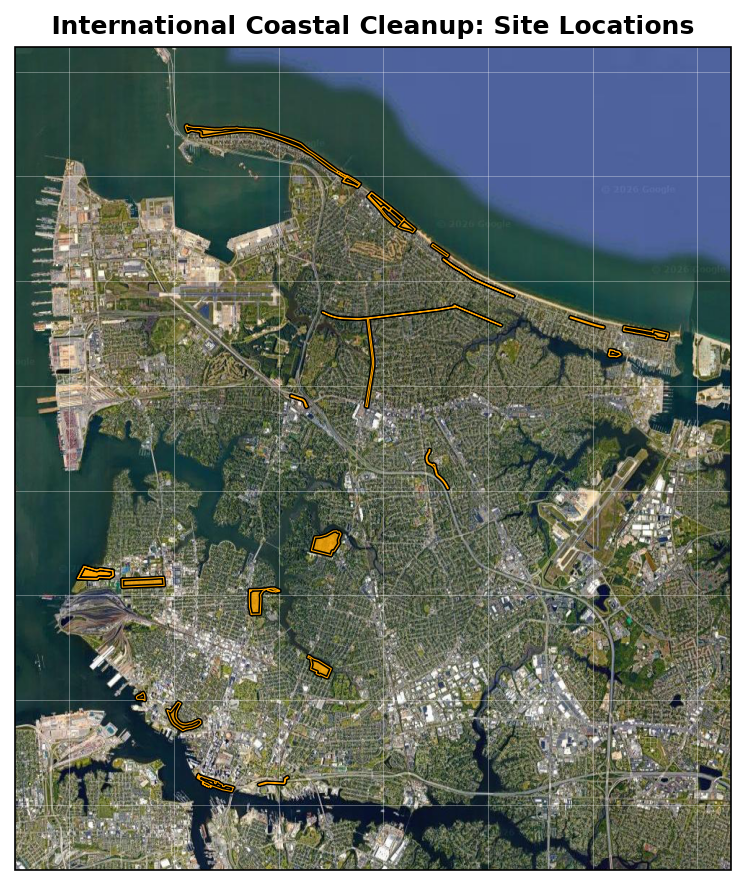

In [46]:
print("Map: cleanup site locations over satellite imagery (full extent)")

# GoogleTiles(style='satellite') fetches real satellite imagery tiles,
# which gives much more visual detail and realism than vector shapefiles at this zoom level
tiler = cimgt.GoogleTiles(style='satellite')

# Create figure
fig = plt.figure(figsize=(7,6), dpi=150)

# Use the tile source's own coordinate reference system for the axes, so the satellite imagery
# and everything drawn on top of it share a consistent projection
ax = plt.axes(projection=tiler.crs)

# Set map extent using the original lat/lon geometries (plottable.geometry), since set_extent()
# expects coordinates in the crs passed to it (PlateCarree = lat/lon), not the pre-projected
# Web Mercator coordinates used for plotting below
minx, miny, maxx, maxy = plottable.total_bounds
pad = 0.015  # degrees of padding around the tightest bounding box
ax.set_extent([minx - pad, maxx + pad, miny - pad, maxy + pad], crs=ccrs.PlateCarree())

# Zoom level 13 gives good street-level detail without requesting an excessive number of tiles
ax.add_image(tiler, 13)

# Draw every polygon in solid orange using the shared helper function, looping over the
# pre-projected Web Mercator geometries (geometry_3857) so no internal reprojection is needed
for geom in plottable.geometry_3857:
    draw_polygon(ax, geom, fill_color='orange')

# Labels intentionally omitted here — with 34 polygons at this zoomed-out extent, labels would
# overlap heavily and become unreadable; the North/South maps below are zoomed in specifically
# to make per-polygon labels legible
# The gridlines themselves still render fine, only the numeric lat/lon labels around the edge are disabled here
ax.gridlines(draw_labels=False, linewidth=0.3, color='white', alpha=0.5)

ax.set_title('International Coastal Cleanup: Site Locations', fontweight='bold')
plt.tight_layout()
plt.show()

Maps: cleanup site locations (North and South Norfolk)


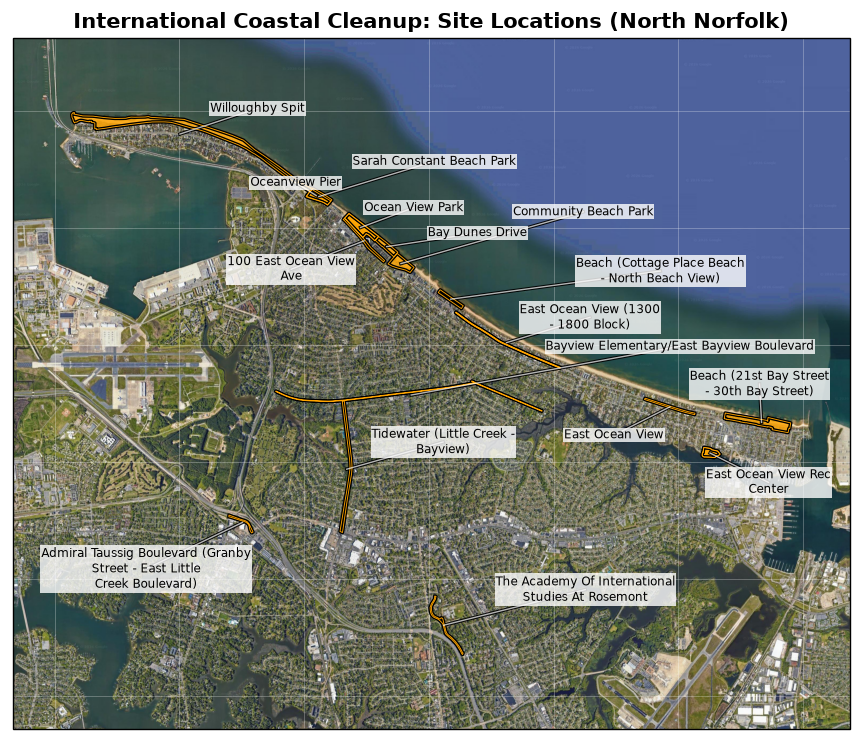

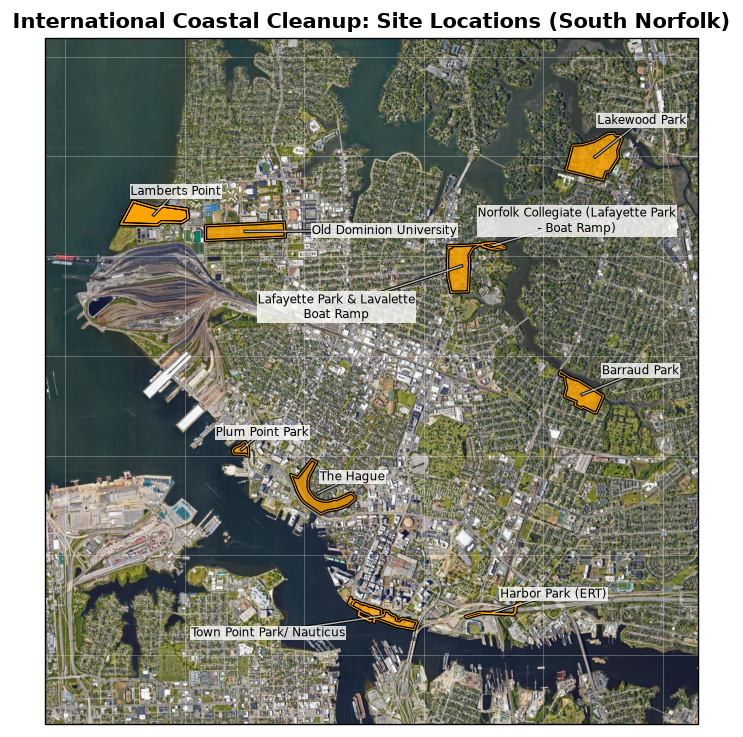

In [47]:
# Make the same map as above, but split into two different maps and give labels
print("Maps: cleanup site locations (North and South Norfolk)")

# Loop over both halves, generating one full figure per half. Bundling label/title/extent info
# together in a dict keeps each half's parameters organized in one place, rather than duplicating
# the whole map-building block twice
halves = [
    {'data': north_half, 'label': 'North Norfolk'},
    {'data': south_half, 'label': 'South Norfolk'}
]

for half in halves:
    gdf = half['data']
    label = half['label']

    tiler = cimgt.GoogleTiles(style='satellite')

    fig = plt.figure(figsize=(7,6), dpi=125)
    ax = plt.axes(projection=tiler.crs)

    # Compute the extent from just this half's bounding box, so each map zooms in tightly
    # around only its own polygons
    minx, miny, maxx, maxy = gdf.total_bounds
    pad = 0.0095  # Slightly smaller padding than the full-extent map, since these views are already zoomed in
    ax.set_extent([minx - pad, maxx + pad, miny - pad, maxy + pad], crs=ccrs.PlateCarree())

    # Higher zoom level (15 vs. 13 on the full-extent map) requests more detailed imagery tiles
    ax.add_image(tiler, 15)

    # Draw each polygon in this half using the shared fill/outline/border helper
    for geom in gdf.geometry_3857:
        draw_polygon(ax, geom, fill_color='orange')

    # Add a small Area-name label near each polygon, since there's enough room at this zoom
    # level for labels to be readable without heavy overlap
    add_area_labels(ax, gdf)

    ax.gridlines(draw_labels=False, linewidth=0.3, color='white', alpha=0.5)
    ax.set_title(f'International Coastal Cleanup: Site Locations ({label})', fontweight='bold')
    plt.tight_layout()
    plt.show()  # Called inside the loop, so each half renders as its own separate figure

Map: cleanup sites colored by average litter collected (full extent)


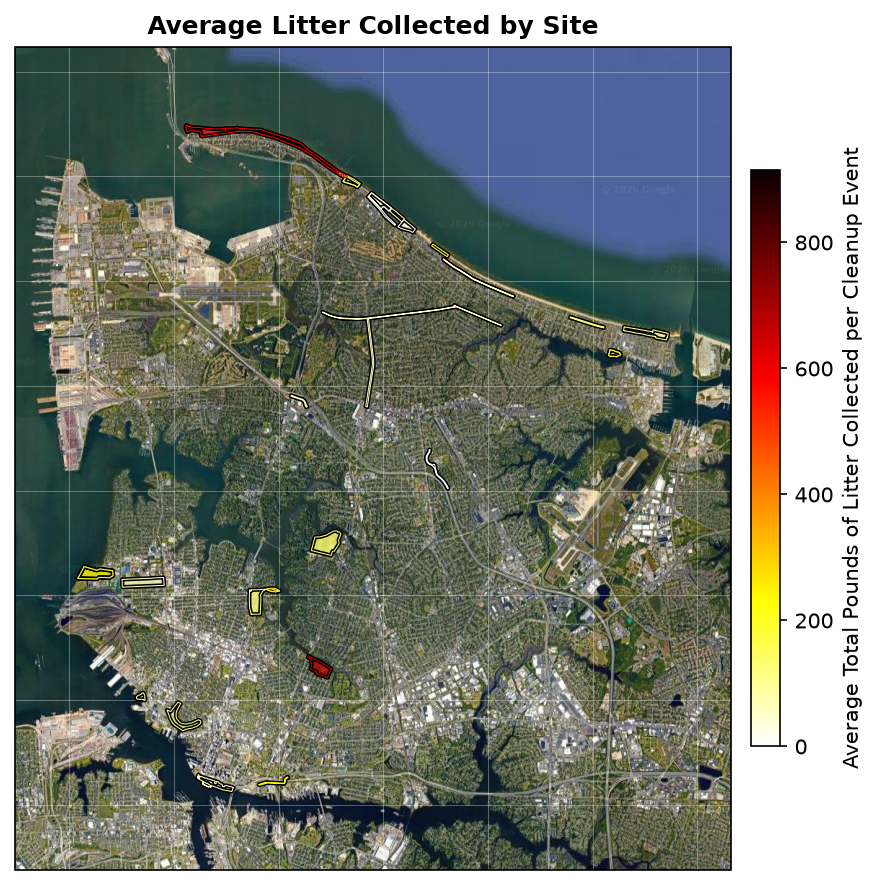

In [48]:
# Now, make a cloropleth map showing variable averages by location
print("Map: cleanup sites colored by average litter collected (full extent)")

# Metric to color the polygons by — swap this to any column in metric_cols
# (e.g. 'Total Items Collected', 'Cigarette Butts') to color by a different variable instead
metric_col = 'Total Pounds of Litter Collected'

tiler = cimgt.GoogleTiles(style='satellite')

fig = plt.figure(figsize=(7,6), dpi=150)
ax = plt.axes(projection=tiler.crs)

minx, miny, maxx, maxy = plottable.total_bounds
pad = 0.015
ax.set_extent([minx - pad, maxx + pad, miny - pad, maxy + pad], crs=ccrs.PlateCarree())
ax.add_image(tiler, 13)

# Set up a color scale spanning the full range of the chosen metric across all Areas that have
# a value. Computing vmin/vmax here (from the full plottable table) — rather than separately in
# each North/South cell — is what lets all 3 choropleth maps share one consistent color scale
vmin = plottable[metric_col].min()
vmax = plottable[metric_col].max()
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.colormaps['hot_r']  # Reversed "hot" colormap: dark/black (low) -> red -> orange -> pale yellow (high)

# Draw each polygon using its own data-driven color: get_fill_color() looks up this row's metric
# value and converts it into a color (or gray, if missing), and draw_polygon() renders it in the
# same fill/outline/border style used by the site-location maps above
for _, row in plottable.iterrows():
    fill_color = get_fill_color(row[metric_col], cmap, norm)
    draw_polygon(ax, row['geometry_3857'], fill_color=fill_color)

ax.gridlines(draw_labels=False, linewidth=0.3, color='white', alpha=0.5)

# Build a colorbar as a legend for what the fill colors represent. ScalarMappable pairs the
# same norm/cmap used for the polygons with an empty data array (set_array([])), which is a
# standard matplotlib pattern for creating a colorbar that isn't tied to a specific plotted image
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', shrink=0.7, pad=0.02)
cbar.set_label(f'Average {metric_col} per Cleanup Event')

ax.set_title('Average Litter Collected by Site', fontweight='bold')
plt.tight_layout()
plt.show()

Maps: cleanup sites colored by average litter collected (North and South Norfolk)


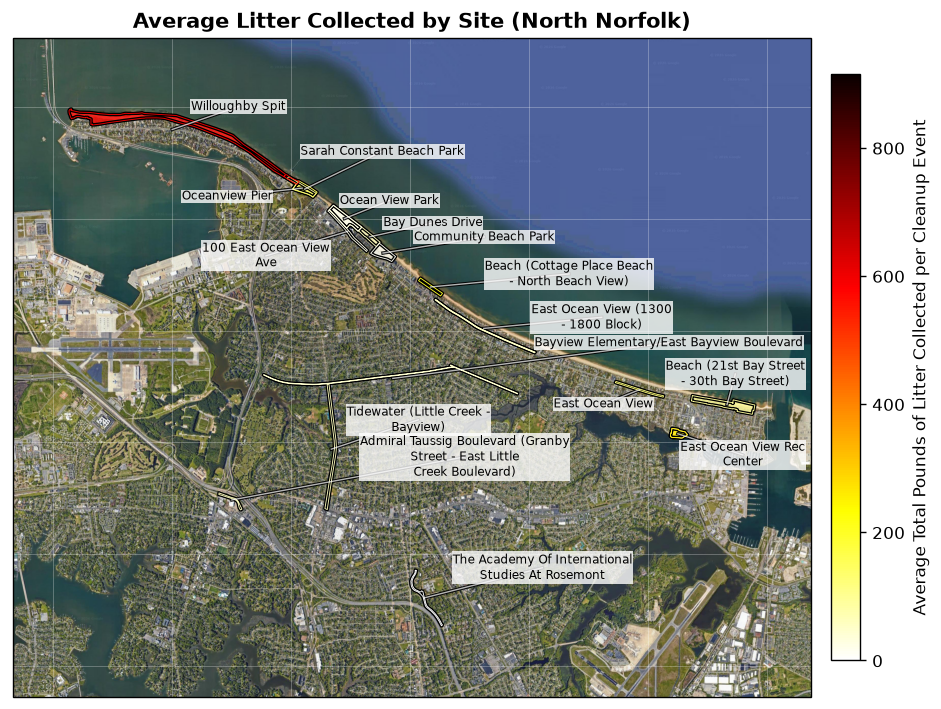

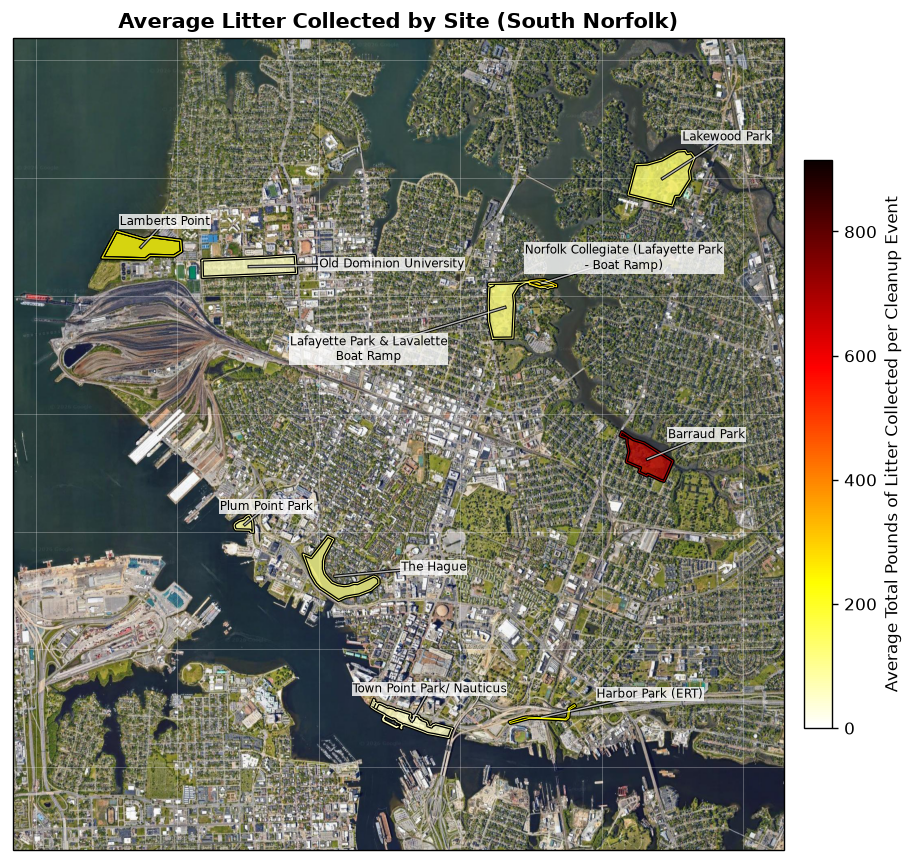

In [49]:
# Make the same cloropleth map as above, but split into two different maps and give labels
print("Maps: cleanup sites colored by average litter collected (North and South Norfolk)")

# Reuses metric_col, vmin, vmax, norm, and cmap from the full-extent choropleth cell above,
# so all 3 choropleth maps (full extent + these 2 halves) share one consistent color scale
halves = [
    {'data': north_half, 'label': 'North Norfolk'},
    {'data': south_half, 'label': 'South Norfolk'}
]

for half in halves:
    gdf = half['data']
    label = half['label']

    tiler = cimgt.GoogleTiles(style='satellite')
    fig = plt.figure(figsize=(8,7), dpi=125)
    ax = plt.axes(projection=tiler.crs)

    minx, miny, maxx, maxy = gdf.total_bounds
    pad = 0.0095
    ax.set_extent([minx - pad, maxx + pad, miny - pad, maxy + pad], crs=ccrs.PlateCarree())
    ax.add_image(tiler, 15)

    # Draw each polygon using its own data-driven color, via the same helper functions used
    # by the full-extent choropleth map
    for _, row in gdf.iterrows():
        fill_color = get_fill_color(row[metric_col], cmap, norm)
        draw_polygon(ax, row['geometry_3857'], fill_color=fill_color)

    add_area_labels(ax, gdf)

    ax.gridlines(draw_labels=False, linewidth=0.3, color='white', alpha=0.5)

    # Redraw the same colorbar on each half's map, so each one can be read on its own without
    # needing to cross-reference the full-extent map's legend
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', shrink=0.7, pad=0.02)
    cbar.set_label(f'Average {metric_col} per Cleanup Event')

    ax.set_title(f'Average Litter Collected by Site ({label})', fontweight='bold')
    plt.tight_layout()
    plt.show()

Map: cleanup sites colored by items collected per volunteer-hour (full extent)


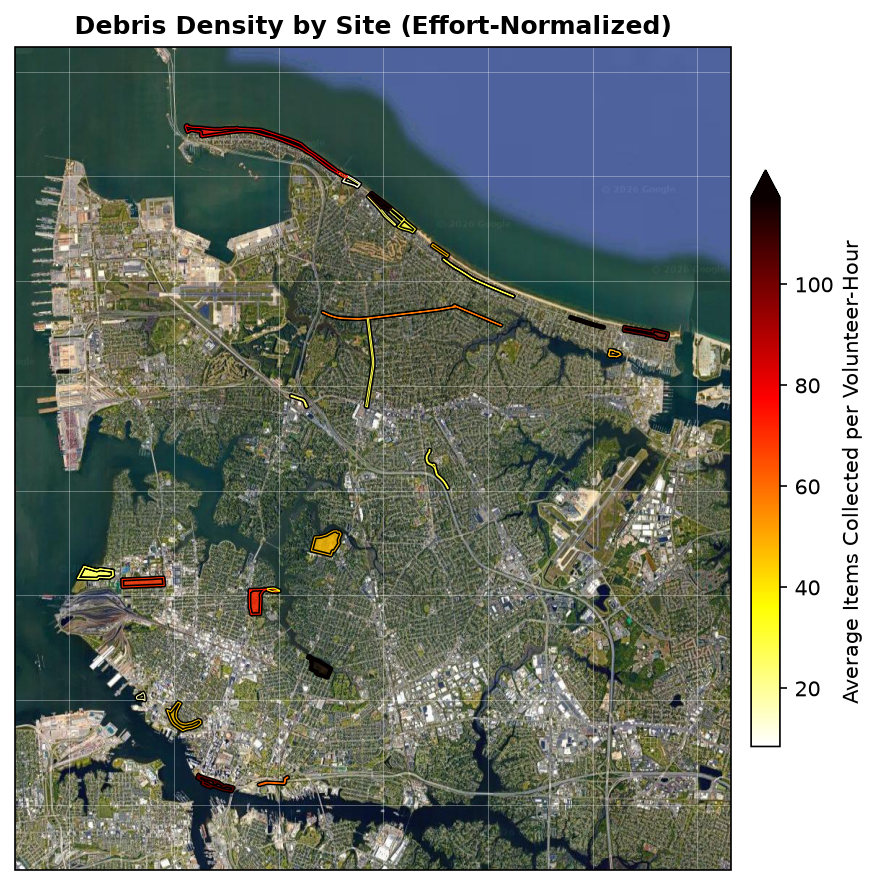

In [50]:
# The following maps color each site by average items collected per volunteer-hour, rather than raw 
# totals — highlighting sites that yield a lot of debris relative to the effort spent finding it, as 
# opposed to sites that are high-yield mainly because they attract large volunteer turnouts.
print("Map: cleanup sites colored by items collected per volunteer-hour (full extent)")

# Switch the metric being mapped — everything else in this cell follows the same pattern as the
# Total Pounds of Litter Collected choropleth above
metric_col = 'Items per Volunteer Hour'

tiler = cimgt.GoogleTiles(style='satellite')

fig = plt.figure(figsize=(7,6), dpi=150)
ax = plt.axes(projection=tiler.crs)

minx, miny, maxx, maxy = plottable.total_bounds
pad = 0.015
ax.set_extent([minx - pad, maxx + pad, miny - pad, maxy + pad], crs=ccrs.PlateCarree())
ax.add_image(tiler, 13)

# Cap the color scale at the 90th percentile rather than the true max. A single extreme value
# (East Ocean View (1300-1800 Block), whose 2-volunteer/4-hour event from the Q5 anecdote works
# out to ~1,226 items/volunteer-hour) would otherwise compress every other site's color toward
# the pale end of a linear scale. clip=True makes any value above vmax render as the same
# fully-saturated top color, rather than being pushed off-scale or causing an error
vmin = plottable[metric_col].min()
vmax = plottable[metric_col].quantile(0.90)
norm = mcolors.Normalize(vmin=vmin, vmax=vmax, clip=True)
cmap = plt.colormaps['hot_r'] # Reused for visual consistency with the litter-pounds choropleth

for _, row in plottable.iterrows():
    fill_color = get_fill_color(row[metric_col], cmap, norm)
    draw_polygon(ax, row['geometry_3857'], fill_color=fill_color)

ax.gridlines(draw_labels=False, linewidth=0.3, color='white', alpha=0.5)

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', shrink=0.7, pad=0.02, extend='max')
cbar.set_label('Average Items Collected per Volunteer-Hour')

ax.set_title('Debris Density by Site (Effort-Normalized)', fontweight='bold')
plt.tight_layout()
plt.show()

Maps: cleanup sites colored by items collected per volunteer-hour (North and South Norfolk)


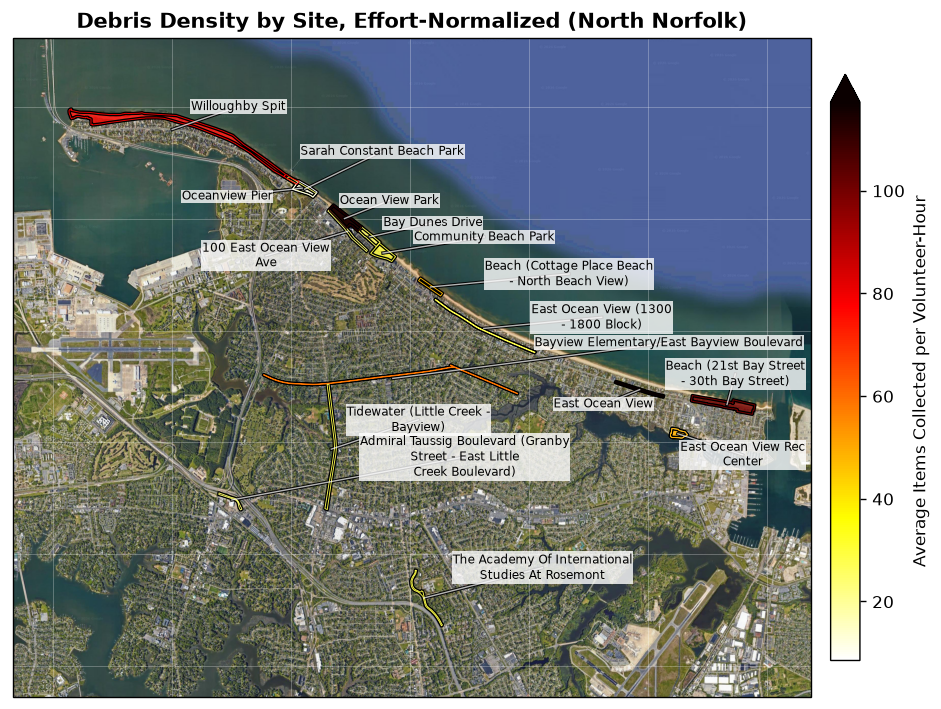

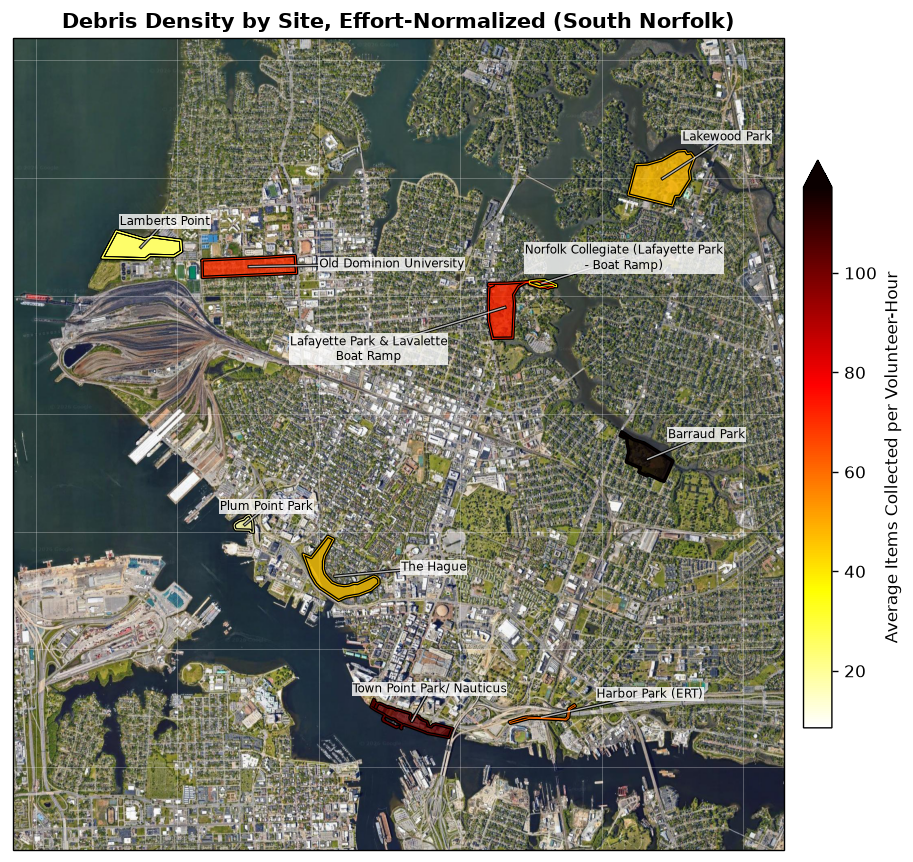

In [51]:
print("Maps: cleanup sites colored by items collected per volunteer-hour (North and South Norfolk)")

# Reuses metric_col, vmin, vmax, norm, and cmap from the full-extent cell directly above, so all
# 3 maps for this metric (full extent + these 2 halves) share one consistent color scale
halves = [
    {'data': north_half, 'label': 'North Norfolk'},
    {'data': south_half, 'label': 'South Norfolk'}
]

for half in halves:
    gdf = half['data']
    label = half['label']

    tiler = cimgt.GoogleTiles(style='satellite')

    fig = plt.figure(figsize=(8,7), dpi=125)
    ax = plt.axes(projection=tiler.crs)

    minx, miny, maxx, maxy = gdf.total_bounds
    pad = 0.0095
    ax.set_extent([minx - pad, maxx + pad, miny - pad, maxy + pad], crs=ccrs.PlateCarree())
    ax.add_image(tiler, 15)

    for _, row in gdf.iterrows():
        fill_color = get_fill_color(row[metric_col], cmap, norm)
        draw_polygon(ax, row['geometry_3857'], fill_color=fill_color)

    add_area_labels(ax, gdf)

    ax.gridlines(draw_labels=False, linewidth=0.3, color='white', alpha=0.5)

    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', shrink=0.7, pad=0.02, extend='max')
    cbar.set_label('Average Items Collected per Volunteer-Hour')

    ax.set_title(f'Debris Density by Site, Effort-Normalized ({label})', fontweight='bold')
    plt.tight_layout()
    plt.show()

--------------------------------------------------------------------------------------

Mapping the sites reveals a pattern not evident from the tabular data alone. Cleanup locations are heavily concentrated along the northern shoreline (Ocean View / Willoughby Spit corridor) and near the Elizabeth River in South Norfolk. In contrast, there are fewer inland sites, which aligns with the dataset's focus on the International Coastal Cleanup initiative—primarily targeting areas where coastal debris naturally gathers. The full Keep Norfolk Beautiful Adopt-A-Spot (AAS) layer ( https://arcg.is/09G9zq ) shows many additional roadside and inland cleanup spots.

The site-location and choropleth maps above also provide a spatial perspective on the Q5 outlier analysis. Barraud Park's polygon stands out on the average litter choropleth map, showing one of the highest average litter totals. This visually supports the earlier observation that it is a recurring debris hotspot, rather than the result of unusually frequent cleanups. Willoughby Spit is the second location that stands out on this map, but it did not appear in the outlier operations.

The color scale on the effort-density choropleth maps is capped at the 90th percentile rather than the actual maximum because a single event skews the raw data: `East Ocean View (1300 - 1800 Block)`'s 2016 event. This event was flagged in Q5 as a potential data-entry error (two volunteers recorded only 4 hours to gather 4,904 items), resulting in approximately 1,226 items per volunteer-hour—roughly six times higher than the next highest site. Without capping, this outlier would cause all other sites' colors to shift toward the pale end of the scale.

The maps also clarify that while Willoughby Spit scored high on the raw litter totals like Barraud Park, it was not flagged as an outlier because litter collection was consistently high at nearly every visit. Once debris counts are normalized by volunteer-hours, Willoughby Spit drops in ranking behind Ocean View Park, East Ocean View, and Barraud Park. This indicates that its high raw totals are likely due to longer or larger cleanup efforts rather than a higher density of debris. Conversely, Barraud Park remains near the top even after normalization, confirming that its high yield is not solely due to effort.

Note that three areas with identified locations but no recorded cleanup data—excluded from these maps due to Q3 no-data-row removal—are not shown here. Additionally, two areas have cleanup data, but I couldn't determine their specific locations within Norfolk.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## Q6) Relationships between variables

How do your variables relate to each other? You might look at correlations, scatter plots, and/or correlation matrices.

The following code cells examine how the key numeric variables relate using a correlation matrix, a heatmap, and scatter plots. The focus is on the 5 summary-level variables plus the two most common debris categories identified in Q4 (`Cigarette Butts` and `Plastic Pieces`), since a full correlation matrix across all 47 debris-item columns would be too large to interpret visually.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

In [52]:
print("Correlation matrix for key variables:")

# Select the 5 summary-level variables plus the 2 most common debris categories from Q4
corr_cols = ['Total Items Collected', 'Total Pounds of Litter Collected', 'Number of Volunteers',
             'Volunteer Hours', 'Number of Miles', 'Cigarette Butts', 'Plastic Pieces']

# .corr() computes pairwise Pearson correlation coefficients between all selected columns
corr_matrix = data[corr_cols].corr()
corr_matrix.round(2)

Correlation matrix for key variables:


,Total Items Collected,Total Pounds of Litter Collected,Number of Volunteers,Volunteer Hours,Number of Miles,Cigarette Butts,Plastic Pieces
Total Items Collected,1.00,0.66,0.72,0.80,0.19,0.74,0.64
Total Pounds of Litter Collected,0.66,1.00,0.67,0.83,0.19,0.43,0.21
Number of Volunteers,0.72,0.67,1.00,0.90,0.49,0.46,0.35
Volunteer Hours,0.80,0.83,0.90,1.00,0.28,0.53,0.33
Number of Miles,0.19,0.19,0.49,0.28,1.00,0.04,0.15
Cigarette Butts,0.74,0.43,0.46,0.53,0.04,1.00,0.22
Plastic Pieces,0.64,0.21,0.35,0.33,0.15,0.22,1.00


Heatmap: correlation matrix for key variables


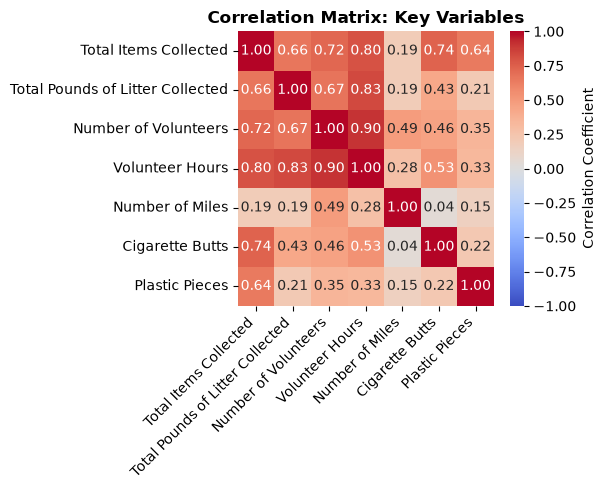

In [53]:
print("Heatmap: correlation matrix for key variables")

# Create a figure/axis pair, sized smaller so it renders well within the notebook width
fig, ax = plt.subplots(figsize=(6,5), dpi=100)

# Plot the correlation matrix as a heatmap, with values annotated in each cell
# vmin/vmax fix the color scale to the full possible correlation range (-1 to 1)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax,
            cbar_kws={'label': 'Correlation Coefficient'})

ax.set_title('Correlation Matrix: Key Variables', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Scatter plot: Volunteer Hours vs. Total Items Collected


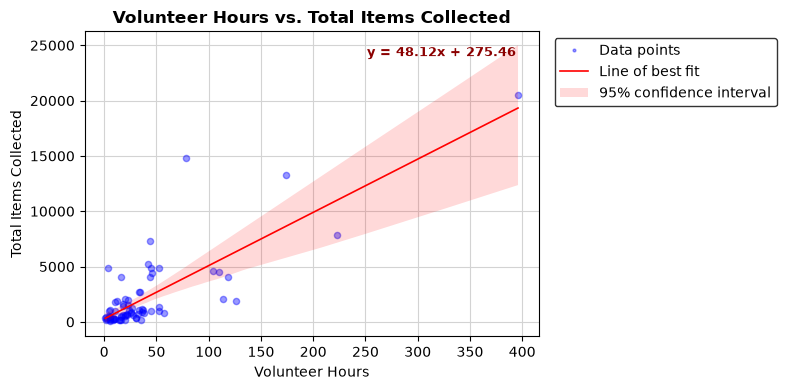

In [54]:
print("Scatter plot: Volunteer Hours vs. Total Items Collected")

fig, ax = plt.subplots(figsize=(8,4), dpi=100)
ax.set_axisbelow(True)
ax.grid(True, color='lightgray')

# regplot draws a scatter plot with a fitted linear regression line overlaid,
# which makes the direction and strength of the relationship easier to see
sns.regplot(data=data, x='Volunteer Hours', y='Total Items Collected', ax=ax,
            color='red', # sets the default color for the line and confidence band
            scatter_kws={'color': 'blue', 'alpha': 0.4, 's': 20}, # overrides just the points to be small, semi-transparent blue dots
            line_kws={'linewidth': 1.2}) 

# Compute the slope and intercept of the fitted line to display as a y=mx+b equation
slope, intercept, r_value, p_value, std_err = stats.linregress(data['Volunteer Hours'], data['Total Items Collected'])
eq_text = f"y = {slope:.2f}x + {intercept:.2f}"
ax.text(0.95, 0.95, eq_text, transform=ax.transAxes, ha='right', va='top',
        color='darkred', fontsize=9, fontweight='bold')

# Set the plot title
ax.set_title('Volunteer Hours vs. Total Items Collected', fontweight='bold')

# Build custom legend handles for the 3 plot elements: points, regression line, and confidence band
point_handle = mlines.Line2D([], [], marker='o', linestyle='None', color='blue', alpha=0.4, 
                              markersize=2, label='Data points')
line_handle = mlines.Line2D([], [], color='red', linewidth=1.2, label='Line of best fit')
ci_handle = mpatches.Patch(facecolor='red', alpha=0.15, label='95% confidence interval')

# Place the legend box outside the plot area, to the right, with no title
ax.legend(handles=[point_handle, line_handle, ci_handle], loc='upper left', bbox_to_anchor=(1.02, 1),
          frameon=True, edgecolor='black', facecolor='white')

plt.tight_layout()
plt.show()

Scatter plot: Number of Miles vs. Total Items Collected


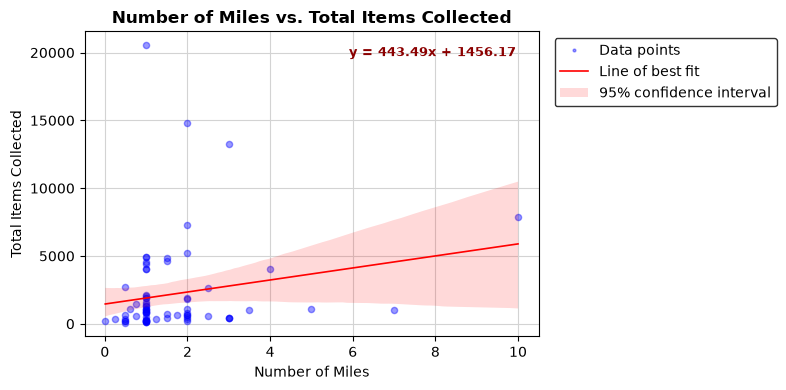

In [55]:
print("Scatter plot: Number of Miles vs. Total Items Collected")

fig, ax = plt.subplots(figsize=(8,4), dpi=100)
ax.set_axisbelow(True)
ax.grid(True, color='lightgray')

# regplot draws a scatter plot with a fitted linear regression line overlaid,
# which makes the direction and strength of the relationship easier to see
sns.regplot(data=data, x='Number of Miles', y='Total Items Collected', ax=ax,
            color='red', # sets the default color for the line and confidence band
            scatter_kws={'color': 'blue', 'alpha': 0.4, 's': 20}, # overrides just the points to be small, semi-transparent blue dots
            line_kws={'linewidth': 1.2})

# Compute the slope and intercept of the fitted line to display as a y=mx+b equation
slope, intercept, r_value, p_value, std_err = stats.linregress(data['Number of Miles'], data['Total Items Collected'])
eq_text = f"y = {slope:.2f}x + {intercept:.2f}"
ax.text(0.95, 0.95, eq_text, transform=ax.transAxes, ha='right', va='top',
        color='darkred', fontsize=9, fontweight='bold')

# Set the plot title
ax.set_title('Number of Miles vs. Total Items Collected', fontweight='bold')

# Build custom legend handles for the 3 plot elements: points, regression line, and confidence band
point_handle = mlines.Line2D([], [], marker='o', linestyle='None', color='blue', alpha=0.4, 
                              markersize=2, label='Data points')
line_handle = mlines.Line2D([], [], color='red', linewidth=1.2, label='Line of best fit')
ci_handle = mpatches.Patch(facecolor='red', alpha=0.15, label='95% confidence interval')

# Place the legend box outside the plot area, to the right, with no title
ax.legend(handles=[point_handle, line_handle, ci_handle], loc='upper left', bbox_to_anchor=(1.02, 1),
          frameon=True, edgecolor='black', facecolor='white')

plt.tight_layout()
plt.show()

--------------------------------------------------------------------------------------

The heatmap and scatter plots point to a few clear relationships. `Volunteer Hours` is the variable most strongly correlated with `Total Items Collected` (r ≈ 0.81) and `Total Pounds of Litter Collected` (r ≈ 0.84), which makes intuitive sense: more cumulative person-hours spent searching should yield more debris found and removed. `Number of Volunteers` and `Volunteer Hours` are themselves very strongly correlated (r ≈ 0.91), which is expected since more people at an event generally means more total hours logged, and suggests these two variables largely capture the same underlying factor (overall effort) rather than independent information.

`Number of Miles`, by contrast, is only weakly correlated with `Total Items Collected` (r ≈ 0.22) and every other variable in the matrix. This suggests that covering more distance during a cleanup does not, on its own, predict how much debris is found — a short, concentrated cleanup effort at a debris-dense site can outperform a longer walk through a cleaner area. This is consistent with the Q5 finding that some outlier events (e.g. Barraud Park) posted very high debris totals despite covering only 1–2 miles.

`Cigarette Butts` correlates moderately with `Total Items Collected` (r ≈ 0.74), which follows directly from Q4's finding that cigarette butts make up the largest single share of items collected across the dataset — events with a high cigarette butt count are, almost by definition, likely to have a high overall item count.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## Q7) Initial conclusions

Combining insights from Q1–Q6 and the bonus mapping from Q5, a few initial conclusions emerge from this EDA of Norfolk's International Coastal Cleanup data:

- The dataset covers a small but mostly complete record of cleanup events since 2016. Several count columns needed cleaning (removing commas) before analysis.
- Removing missing data was not straightforward since 0s in all fields indicated a data gap, but 0s are still valid entries in most of the columns. After removing 4 entries with zero volunteers, hours, and miles (not actual cleanups but data gaps), 73 events across 36 sites remain.
- Debris counts are highly right-skewed, where most events collect moderate litter, but a few gather enormous amounts, raising the average well above the median.
- Cigarette butts are the most collected item, averaging about 480 per cleanup. This average is nearly twice that of plastic pieces, aligning with patterns seen in coastal cleanup reports.
- A few high-volume outliers, especially at Barraud Park, suggest actual site-level differences rather than just larger volunteer turnout. Furthermore, Barraud Park had outliers in all 6 cleanups, far above the dataset's average outlier rate of 13.7%, despite not being the most frequently cleaned site.
- The total debris collected correlates most strongly with cumulative volunteer hours, and only weakly with miles covered, indicating debris density and volunteer effort matter more than distance covered.
- Spatial mapping shows sites cluster mainly along the northern shoreline (Ocean View / Willoughby Spit) and around the Elizabeth River in South Norfolk, with few inland locations. The choropleth map highlights Barraud Park's high litter totals, confirming its status as a significant outlier geographically and numerically.

These insights suggest future cleanup efforts could focus on high-yield sites like Barraud Park, and that cigarette butt litter may benefit from targeted prevention tools like receptacles. Understanding why certain sites gather more debris (tide flow, stormwater outlets, traffic, wind) would require data beyond this dataset, as would verifying whether site clustering reflects true debris accumulation or volunteer focus patterns.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------